## Tidy version of ML code

for mutli model comparison

In [2]:
import iris
import iris.coord_categorisation as cat
import iris.analysis as ia
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cf_units
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.metrics import pairwise_distances




In [3]:
TARGET_TIME_UNITS = cf_units.Unit(
        'days since 2015-01-01 00:00:00', 
        calendar=cf_units.CALENDAR_GREGORIAN
    )

def normalize_time_to_target_units(cube, target_units=TARGET_TIME_UNITS):
    """Convert cube's 'time' points (and bounds) to target units/calendar and sort."""
    if not cube.coords('time'):
        raise ValueError("Cube has no 'time' coordinate.")
    time = cube.coord('time')

    # Convert numeric points -> datetimes via the current units/calendar
    current_units = time.units
    datetimes = current_units.num2date(time.points)

    # Re-encode datetimes -> numeric points in target units
    new_points = target_units.date2num(datetimes)
    time.units = target_units
    time.points = new_points

    # Preserve bounds if present
    if time.has_bounds():
        lower = current_units.num2date(time.bounds[:, 0])
        upper = current_units.num2date(time.bounds[:, 1])
        new_bounds = np.column_stack([
            target_units.date2num(lower),
            target_units.date2num(upper)
        ])
        time.bounds = new_bounds

    # Ensure monotonic order along time
    order = np.argsort(time.points)
    if not np.all(order == np.arange(len(order))):
        cube = cube[order]

    return cube

def concat_time_cubes(cubes):
    """Equalise attributes, unify time units, sort by first time, and concatenate."""
    # Harmonise non-critical attributes (title, history, etc.)
    iris.util.equalise_attributes(cubes)

    # Unify time units (safe even after explicit normalization)
    iris.util.unify_time_units(cubes)

    # Sort cubes by their first time point to be safe
    def first_time_dt(c):
        t = c.coord('time')
        return t.units.num2date(t.points[0])
    cubes.sort(key=first_time_dt)

    # Concatenate into a single continuous cube
    combined = iris.cube.CubeList(cubes).concatenate_cube()
    return combined

def check_daily_continuity(cube):
    """Optional: simple continuity check for daily cadence."""
    t = cube.coord('time')
    # Convert to datetime64 for delta checks
    times = np.array(t.units.num2date(t.points), dtype='datetime64[ns]')
    diffs = np.diff(times)
    unique_steps = np.unique(diffs)
    strictly_increasing = np.all(diffs > np.timedelta64(0, 'D'))
    daily = np.all(unique_steps == np.timedelta64(1, 'D'))
    return strictly_increasing, daily, unique_steps

def read_clean_data(model_path, restan = False):
    #------------read in obs data ----------------------------
    DATADIR = '/data/users/emily.wright/old-data/emwright/model_inputs/ML_Proj_data/Data' #new VDI
    ERA5_precip = iris.load_cube(f'{DATADIR}/climate/amazon_lowlandprecip_ERA5.nc')
    ERA5_temp = iris.load_cube(f'{DATADIR}/climate/amazon_lowlandtemp_ERA5.nc')
    phosphorous = iris.load_cube(f'{DATADIR}/soil/amazon_lowlandP.nc')

    phos_regrid = phosphorous.regrid(ERA5_temp, iris.analysis.Linear())

    # save lat and lon coords of cube
    lats = ERA5_temp.coord('latitude').points
    lons = ERA5_temp.coord('longitude').points
    #make a meshgrid
    lons, lats = np.meshgrid(lons, lats)

    df_era = pd.DataFrame({
        'Temperature': ERA5_temp.data.flatten(),
        'Precipitation': ERA5_precip.data.flatten(),
        'Phosphorous': phos_regrid.data.flatten(),
        'Latitude': lats.flatten(),
        'Longitude': lons.flatten()})
    
    df_era.dropna(inplace=True)
    
    ISIMIP_DATADIR = '/data/scratch/emily.wright/ISIMIP_data'
    
    # ---- Load historic and projected cubes individually----
    ISI_driv_precip_2001_2010 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_prAdjust_global_daily_2001_2010.nc')
    ISI_driv_precip_2011_2014 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_prAdjust_global_daily_2011_2014.nc')
    ISI_driv_temp_2001_2010 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_tasAdjust_global_daily_2001_2010.nc')
    ISI_driv_temp_2011_2014 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_tasAdjust_global_daily_2011_2014.nc')
    ISI_precip_2081_2090 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_prAdjust_global_daily_2081_2090.nc')
    ISI_precip_2091_2100 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_prAdjust_global_daily_2091_2100.nc')
    ISI_temp_2081_2090 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_tasAdjust_global_daily_2081_2090.nc')
    ISI_temp_2091_2100 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_tasAdjust_global_daily_2091_2100.nc')



    # ---- Normalize each cube's time to the target units ----
    precip_driv_cubes = [
        normalize_time_to_target_units(ISI_driv_precip_2001_2010),
        normalize_time_to_target_units(ISI_driv_precip_2011_2014),
    ]
    temp_driv_cubes = [
        normalize_time_to_target_units(ISI_driv_temp_2001_2010),
        normalize_time_to_target_units(ISI_driv_temp_2011_2014),
    ]
    precip_proj_cubes = [
        normalize_time_to_target_units(ISI_precip_2081_2090),
        normalize_time_to_target_units(ISI_precip_2091_2100),
    ]
    temp_proj_cubes = [
        normalize_time_to_target_units(ISI_temp_2081_2090),
        normalize_time_to_target_units(ISI_temp_2091_2100),
    ]

    # ---- Concatenate into continuous series ----
    ISI_driv_precip = concat_time_cubes(precip_driv_cubes)
    ISI_driv_temp   = concat_time_cubes(temp_driv_cubes)
    ISI_precip_proj = concat_time_cubes(precip_proj_cubes)
    ISI_temp_proj   = concat_time_cubes(temp_proj_cubes)


    # if data doesnt have 'year' auxiliary coordinate derived from 'time'
    for cube in [ISI_driv_precip, ISI_driv_temp, ISI_precip_proj, ISI_temp_proj]:
        if not cube.coords('year'):
            cat.add_year(cube, 'time', name='year') 


    #Aggregate by the 'year' category using mean
    annual_mean_precip_driv = ISI_driv_precip.aggregated_by('year', ia.MEAN)
    annual_mean_temp_driv = ISI_driv_temp.aggregated_by('year', ia.MEAN)
    annual_mean_precip_proj = ISI_precip_proj.aggregated_by('year', ia.MEAN)
    annual_mean_temp_proj = ISI_temp_proj.aggregated_by('year', ia.MEAN)

    #now average over the yearly data to get a climatology
    ISI_driv_precip_clim = annual_mean_precip_driv.collapsed('year', ia.MEAN)
    ISI_driv_temp_clim = annual_mean_temp_driv.collapsed('year', ia.MEAN)
    ISI_precip_clim_proj = annual_mean_precip_proj.collapsed('year', ia.MEAN)
    ISI_temp_clim_proj = annual_mean_temp_proj.collapsed('year', ia.MEAN)

    #convert temperature from K to C
    ISI_driv_temp_clim.data = ISI_driv_temp_clim.data - 273.15
    ISI_temp_clim_proj.data = ISI_temp_clim_proj.data - 273.15

    #convert precipitation from kg m-2 s-1 to mm/year
    ISI_driv_precip_clim.data = ISI_driv_precip_clim.data * 86400 * 365
    ISI_precip_clim_proj.data = ISI_precip_clim_proj.data * 86400 * 365
    

    #regrid to ERA5 grid
    ISI_driv_precip_regrid = ISI_driv_precip_clim.regrid(ERA5_precip, iris.analysis.Linear())
    ISI_driv_temp_regrid = ISI_driv_temp_clim.regrid(ERA5_temp, iris.analysis.Linear())
    ISI_precip_regrid_proj = ISI_precip_clim_proj.regrid(ERA5_precip, iris.analysis.Linear())
    ISI_temp_regrid_proj = ISI_temp_clim_proj.regrid(ERA5_temp, iris.analysis.Linear())
 
    mask = (ERA5_temp.data.mask) + (np.isnan(ERA5_temp.data)) + (np.abs(ERA5_temp.data) >= 1e10)

    #where mask is true set ISI_temp_regrid.data to nan
    ISI_driv_temp_regrid.data = np.where(mask, np.nan, ISI_driv_temp_regrid.data)
    ISI_temp_regrid_proj.data = np.where(mask, np.nan, ISI_temp_regrid_proj.data)   
    ISI_precip_regrid_proj.data = np.where(mask, np.nan, ISI_precip_regrid_proj.data)
    ISI_driv_precip_regrid.data = np.where(mask, np.nan, ISI_driv_precip_regrid.data)

    #make pandasdataframes of the regridded ISIMIP data
    df = pd.DataFrame({
        'Temperature': ISI_driv_temp_regrid.data.flatten(),
        'Precipitation': ISI_driv_precip_regrid.data.flatten(),
        'Phosphorous': phos_regrid.data.flatten(),
        'Latitude': lats.flatten(),
        'Longitude': lons.flatten()})

    # Drop rows with NaN values
    df.dropna(inplace=True)

    df_proj = pd.DataFrame({
        'Temperature': ISI_temp_regrid_proj.data.flatten(),
        'Precipitation': ISI_precip_regrid_proj.data.flatten(),
        'Phosphorous': phos_regrid.data.flatten(),
        'Latitude': lats.flatten(),
        'Longitude': lons.flatten()})


    # Drop rows with NaN values
    df_proj.dropna(inplace=True)

    #transform temp, precip and phosphorous data
    pt = PowerTransformer(method='yeo-johnson')
    scaler = StandardScaler()

    df_era_trans = pt.fit_transform(df_era[['Temperature', 'Precipitation', 'Phosphorous']])
    df_era_trans = scaler.fit_transform(df_era_trans)
    df_era_trans = pd.DataFrame(df_era_trans, columns=['Temperature', 'Precipitation', 'Phosphorous'])
    df_era_trans['Latitude'] = df_era['Latitude'].values
    df_era_trans['Longitude'] = df_era['Longitude'].values


    df_trans = pt.fit_transform(df[['Temperature', 'Precipitation', 'Phosphorous']])
    df_trans = scaler.fit_transform(df_trans)
    df_trans = pd.DataFrame(df_trans, columns=['Temperature', 'Precipitation', 'Phosphorous'])
    df_trans['Latitude'] = df['Latitude'].values 
    df_trans['Longitude'] = df['Longitude'].values

    #note here choose whether standardise data using fit_trans (new standardisation) or standardise in line with historic data
    df_proj_trans = pt.transform(df_proj[['Temperature', 'Precipitation', 'Phosphorous']])
    if restan == True:
        df_proj_trans = scaler.fit_transform(df_proj_trans)
    else:
        df_proj_trans = scaler.transform(df_proj_trans)
    df_proj_trans = pd.DataFrame(df_proj_trans, columns=['Temperature', 'Precipitation', 'Phosphorous'])
    df_proj_trans['Latitude'] = df_proj['Latitude'].values
    df_proj_trans['Longitude'] = df_proj['Longitude'].values
    

    return df, df_trans, df_proj, df_proj_trans, df_era, df_era_trans

def plot_data(df, df_proj, transformed=False):
    
    # Plot histograms for driving (top row) and projected (bottom row) data
    # sharex_opt = 'col' if transformed is False else False
    sharex_opt = False
    fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=sharex_opt)

    # --- Driving data (2001–2014) ---
    axes[0, 0].hist(df['Temperature'], bins=50, color='blue', alpha=0.7)
    axes[0, 0].set_title('Temperature Distribution (2001–2014)')
    axes[0, 0].set_xlabel('Temperature (°C)')
    axes[0, 0].set_ylabel('Frequency')

    axes[0, 1].hist(df['Precipitation'], bins=50, color='green', alpha=0.7)
    axes[0, 1].set_title('Precipitation Distribution (2001–2014)')
    axes[0, 1].set_xlabel('Precipitation (mm/yr)')
    axes[0, 1].set_ylabel('Frequency')

    axes[0, 2].hist(df['Phosphorous'], bins=50, color='red', alpha=0.7)
    axes[0, 2].set_title('Phosphorous Distribution (2001–2014)')
    axes[0, 2].set_xlabel('Phosphorous')
    axes[0, 2].set_ylabel('Frequency')

    # --- Projected data (2081–2100) ---
    axes[1, 0].hist(df_proj['Temperature'], bins=50, color='blue', alpha=0.7)
    axes[1, 0].set_title('Temperature Distribution (2081–2100)')
    axes[1, 0].set_xlabel('Temperature (°C)')
    axes[1, 0].set_ylabel('Frequency')

    axes[1, 1].hist(df_proj['Precipitation'], bins=50, color='green', alpha=0.7)
    axes[1, 1].set_title('Precipitation Distribution (2081–2100)')
    axes[1, 1].set_xlabel('Precipitation (mm/yr)')
    axes[1, 1].set_ylabel('Frequency')

    axes[1, 2].hist(df_proj['Phosphorous'], bins=50, color='red', alpha=0.7)
    axes[1, 2].set_title('Phosphorous Distribution (2081–2100)')
    axes[1, 2].set_xlabel('Phosphorous')
    axes[1, 2].set_ylabel('Frequency')

    if transformed == False:
        plt.suptitle('Distributions of Temperature, Precipitation, and Phosphorous', fontsize=16)
    else:
        plt.suptitle('Distributions of TRANSFORMED Temperature, Precipitation, and Phosphorous', fontsize=16)
    plt.tight_layout()
    plt.show()

def kmeans_clustering_fit(df, n):
    kmeans = KMeans(n_clusters=n, random_state=42, n_init="auto")
    kmeans.fit(df[['Temperature', 'Precipitation', 'Phosphorous']])
    kmeans_labels = kmeans.labels_
    dist_to_centroids = pairwise_distances(df[['Temperature', 'Precipitation', 'Phosphorous']], kmeans.cluster_centers_, metric='euclidean')
    return kmeans, kmeans_labels, n, dist_to_centroids

def novel(df_historic, df_projected, n, random_state=42):
    """
    Fit KMeans on historic data and identify novel climates in projected data.
    Points in projected data with distance to nearest centroid > mean + 2*std
    are labeled as cluster n (novel climate).
    """
    
    FEATURES = ['Temperature', 'Precipitation', 'Phosphorous']

    X_historic = df_historic[FEATURES].values
    X_projected = df_projected[FEATURES].values

    # Fit KMeans on historic data
    kmeans = KMeans(n_clusters=n, random_state=random_state, n_init="auto")
    kmeans.fit(X_historic)

    # Compute distances to centroids for historic data
    D_historic = pairwise_distances(X_historic, kmeans.cluster_centers_, metric='euclidean')
    min_dist_historic = D_historic.min(axis=1)

    # Compute per-cluster thresholds = mean + 2*std
    thresholds = np.zeros(n)
    for k in range(n):
        labels_historic = kmeans.labels_
        d_k = min_dist_historic[labels_historic == k]
        if len(d_k) > 0:
            thresholds[k] = d_k.mean() + 2.0 * d_k.std(ddof=1)
        else:
            thresholds[k] = np.nan

    # Predict on projected data
    projected_labels = kmeans.predict(X_projected)
    
    # Compute distances to centroids for projected data
    D_projected = pairwise_distances(X_projected, kmeans.cluster_centers_, metric='euclidean')
    min_dist_projected = D_projected.min(axis=1)

    # Mark novel points: where distance exceeds threshold for their assigned cluster
    for i in range(len(X_projected)):
        cluster = projected_labels[i]
        if min_dist_projected[i] > thresholds[cluster]:
            projected_labels[i] = n  # Label as novel cluster

    return kmeans, projected_labels, thresholds

def kmeans_clustering_predict(df_fit, df_proj, n):
    kmeans = KMeans(n_clusters=n, random_state=42, n_init="auto")
    kmeans.fit(df_fit[['Temperature', 'Precipitation', 'Phosphorous']])
    kmeans_labels = kmeans.predict(df_proj[['Temperature', 'Precipitation', 'Phosphorous']])
    dist_to_centroids = pairwise_distances(df_proj[['Temperature', 'Precipitation', 'Phosphorous']], kmeans.cluster_centers_, metric='euclidean')
    return kmeans_labels, n, dist_to_centroids

def plot_clusters(df, kmeans_labels, shared_plot=True, title = "", restan = False, model = "ipsl"):
    # n = len(np.unique(kmeans_labels))
    n = 5
    cmap_alt = plt.cm.colors.ListedColormap(['darkred', 'gold', 'orangered', 'darkgreen', 'dodgerblue'])
    norm = plt.Normalize(vmin=0, vmax=n - 1)

    if model == "ipsl" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered'])
    elif model == "ipsl" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'])

    elif model == "ukesm" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'orangered', 'gold', 'darkred', 'dodgerblue'])
    elif model == "ukesm" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['gold', 'orangered', 'dodgerblue', 'darkred', 'darkgreen'])

    elif model == "gfdl":
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'orangered', 'gold', 'darkred', 'dodgerblue'])
    

    elif model == "mri" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'darkred', 'dodgerblue', 'gold', 'orangered'])
    elif model == "mri" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'])

    elif model == "mpi" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'darkred', 'orangered', 'gold', 'dodgerblue'])
    elif model == "mpi" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'gold', 'orangered', 'darkred', 'dodgerblue'])


    if shared_plot:
        # Layout: top row has 2 plots, bottom row is one merged colorbar axis
        fig = plt.figure(figsize=(18, 7), constrained_layout=True)
        gs = fig.add_gridspec(2, 2, height_ratios=[20, 1])

        # --- Left subplot: 3D feature space ---
        ax1 = fig.add_subplot(gs[0, 0], projection='3d')
        ax1.scatter(
            df["Temperature"],
            df["Precipitation"],
            df["Phosphorous"],
            c=kmeans_labels,
            cmap=cmap_alt,
            alpha=0.4,
            s=10,
            vmin=0, vmax=n - 1
        )
        ax1.set_xlabel('Standardized Temperature', fontsize=14)
        ax1.set_ylabel('Standardized Precipitation', fontsize=14)
        ax1.set_zlabel('Standardized Phosphorous', fontsize=14)
        ax1.tick_params(axis='both', labelsize=12)
        ax1.view_init(elev=30, azim=10)
        ax1.set_title('Feature Space Clusters', fontsize=16)

        # --- Right subplot: spatial map ---
        ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree())
        h2 = ax2.scatter(
            df["Longitude"], df["Latitude"],
            c=kmeans_labels, cmap=cmap_alt, s=1,
            vmin=0, vmax=n - 1,
            transform=ccrs.PlateCarree()
        )
        ax2.coastlines(zorder=-1)
        ax2.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='grey')
        ax2.scatter(
            -60.208056, -2.594167,
            marker='x', color='black', s=65, linewidth=2,
            label="AmazonFACE Site", transform=ccrs.PlateCarree()
        )
        ax2.set_xlabel('Longitude', fontsize=14)
        ax2.set_ylabel('Latitude', fontsize=14)
        ax2.tick_params(axis='both', labelsize=12)
        ax2.set_title(f'Spatial Clusters (k={n})', fontsize=16)
        ax2.legend(loc='lower left', fontsize=12)

        # --- Bottom merged shared colorbar (using map scatter, no alpha) ---
        cax = fig.add_subplot(gs[1, :])
        cbar = fig.colorbar(
            h2, cax=cax, orientation='horizontal',
            boundaries=np.arange(n + 1) - 0.5,
            ticks=np.arange(n)
        )
        cbar.set_label('Cluster', fontsize=14)
        cbar.ax.tick_params(labelsize=12)

    else:
        # Two subplots, each with its own colorbar
        fig = plt.figure(figsize=(18, 7), constrained_layout=True)
        gs = fig.add_gridspec(1, 2)

        # --- Left subplot: 3D feature space ---
        ax1 = fig.add_subplot(gs[0, 0], projection='3d')
        h1 = ax1.scatter(
            df["Temperature"],
            df["Precipitation"],
            df["Phosphorous"],
            c=kmeans_labels,
            cmap=cmap_alt,
            alpha=0.4,
            s=10,
            vmin=0, vmax=n - 1
        )
        ax1.set_xlabel('Standardized Temperature', fontsize=14)
        ax1.set_ylabel('Standardized Precipitation', fontsize=14)
        ax1.set_zlabel('Standardized Phosphorous', fontsize=14)
        ax1.tick_params(axis='both', labelsize=12)
        ax1.view_init(elev=30, azim=10)
        ax1.set_title('Feature Space Clusters', fontsize=16)

        # --- Right subplot: spatial map ---
        ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree())
        h2 = ax2.scatter(
            df["Longitude"], df["Latitude"],
            c=kmeans_labels, cmap=cmap_alt, s=1,
            vmin=0, vmax=n - 1,
            transform=ccrs.PlateCarree()
        )
        ax2.coastlines(zorder=-1)
        ax2.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='grey')
        ax2.scatter(
            -60.208056, -2.594167,
            marker='x', color='black', s=65, linewidth=2,
            label="AmazonFACE Site", transform=ccrs.PlateCarree()
        )
        ax2.set_xlabel('Longitude', fontsize=14)
        ax2.set_ylabel('Latitude', fontsize=14)
        ax2.tick_params(axis='both', labelsize=12)
        ax2.set_title(f'Spatial Clusters (k={n})', fontsize=16)
        ax2.legend(loc='lower left', fontsize=12)

        # Use map scatter (no alpha) as the colorbar mappable for both
        cbar1 = fig.colorbar(
            h2, ax=ax1, orientation='horizontal', pad=0.08,
            boundaries=np.arange(n + 1) - 0.5, ticks=np.arange(n)
        )
        cbar1.set_label('Cluster', fontsize=12)
        cbar1.ax.tick_params(labelsize=10)

        cbar2 = fig.colorbar(
            h2, ax=ax2, orientation='horizontal', pad=0.08,
            boundaries=np.arange(n + 1) - 0.5, ticks=np.arange(n)
        )
        cbar2.set_label('Cluster', fontsize=12)
        cbar2.ax.tick_params(labelsize=10)
    plt.suptitle(title, fontsize=16)
    plt.show()

def plot_feature_space(df, kmeans_labels, proj=False):
    #like above, plot feature space scatter but projected onto 2D plane of temp, precip
        n = len(np.unique(kmeans_labels))
        # Build colormap
        cmap = plt.get_cmap('Spectral', n + 1)
        colors = [cmap(i) for i in range(n + 1)]
        if n == 5:
            colors.pop(3)  # remove yellowish color
        cmap_alt = plt.cm.colors.ListedColormap(colors) 

        if proj == True:
            #reorder the colours to be 0, 2,4,1,3
            cmap_alt = plt.cm.colors.ListedColormap([colors[0], colors[2], colors[4], colors[1], colors[3]])    
        
        fig, ax = plt.subplots(figsize=(10, 7))
        h = ax.scatter(
            df["Temperature"],
            df["Precipitation"],
            c=kmeans_labels,
            cmap=cmap_alt,
            alpha=0.4,
            s=10
        )
        ax.set_xlabel('Standardized Temperature')
        ax.set_ylabel('Standardized Precipitation')
        ax.set_title('Feature Space Clusters (Temp vs Precip)')
        cbar = fig.colorbar(h, ticks=np.arange(n))
        cbar.set_label('Cluster')
        plt.show()

def plot_marg_dist(df, cluster_labels, n, proj = False):

    # Build colormap
    cmap = plt.get_cmap('Spectral', n + 1)
    colors = [cmap(i) for i in range(n + 1)]
    if n == 5:
        colors.pop(3)  # remove yellowish color

    if proj == True:
        #reorder the colours to be 0, 2,4,1,3
        colors = [colors[0], colors[2], colors[4], colors[1], colors[3]]

    fig, axes = plt.subplots(3, 1, figsize=(10, 9))
    features = ['Temperature', 'Precipitation', 'Phosphorous']

    for idx, feature in enumerate(features):
        ax = axes[idx]
        
        # Compute fixed bin edges based on the full dataset range
        feat_min = df[feature].min()
        feat_max = df[feature].max()
        bin_edges = np.linspace(feat_min, feat_max, 151)  # 100 bins of equal width

        # Plot histogram of feature data for each cluster
        for cluster in range(n):
            ax.hist(df.loc[cluster_labels == cluster, feature], bins=bin_edges, color=colors[cluster], alpha=0.7, label=f"Cluster {cluster}")

        # Vertical lines of median and quartiles
        ax.axvline(df[feature].median(), color='grey', linestyle='--', label='Median')
        ax.axvline(df[feature].quantile(0.25), color='grey', linestyle=':', label='Q1')
        ax.axvline(df[feature].quantile(0.75), color='grey', linestyle=':', label='Q3')

        ax.set_xlabel(feature, fontsize=14)
        ax.set_ylabel('Frequency', fontsize=14)
        ax.tick_params(axis='both', labelsize=11)
        
        # Format y-axis to use integer powers of 10
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        
        if idx == 0:
            cluster_handles = [Patch(facecolor=colors[i], label=f"Cluster {i}") for i in range(n)]
            full_dataset_patch = Patch(facecolor='grey', label='All Data')
            ax.legend(handles=cluster_handles + [full_dataset_patch], fontsize=10, loc='upper left')

    plt.tight_layout()
    plt.show()

def plot_marg_dist_new(df, cluster_labels, n, reorder_colors=False, restan = False, combined = False):

    colors = ['darkred', 'gold', 'orangered', 'darkgreen', 'dodgerblue']
    if reorder_colors == True and restan == False:
        colors = ['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered']
    elif reorder_colors == True and restan == True:
        colors = ['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred']

    if combined == True and reorder_colors == False:
        colors = ['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered']  # Add grey for novel cluster
    elif combined == True and reorder_colors == True:
        colors = ['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred']  # Add grey for novel cluster
    
    cmap = plt.cm.colors.ListedColormap(colors[:n])
    
    fig, axes = plt.subplots(3, 1, figsize=(10, 9))
    features = ['Temperature', 'Precipitation', 'Phosphorous']

    for idx, feature in enumerate(features):
        ax = axes[idx]
        
        # Compute fixed bin edges based on the full dataset range
        feat_min = df[feature].min()
        feat_max = df[feature].max()
        bin_edges = np.linspace(feat_min, feat_max, 151)

        # Plot histogram of feature data for each cluster
        for cluster in range(n):
            ax.hist(
                df.loc[cluster_labels == cluster, feature],
                bins=bin_edges,
                color=cmap(cluster),
                alpha=0.4,
                label=f"Cluster {cluster}"
            )

        # Vertical lines of median and quartiles
        ax.axvline(df[feature].median(), color='grey', linestyle='--', label='Median')
        ax.axvline(df[feature].quantile(0.25), color='grey', linestyle=':', label='Q1')
        ax.axvline(df[feature].quantile(0.75), color='grey', linestyle=':', label='Q3')

        ax.set_xlabel(feature, fontsize=14)
        ax.set_ylabel('Frequency', fontsize=14)
        ax.tick_params(axis='both', labelsize=11)
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

        # Expand y-axis to make room for box-and-whisker plots at the top
        y_max = ax.get_ylim()[1]
        # Reserve extra space: (n + 1) box rows (1 overall + n clusters) plus a small padding
        box_height = y_max * 0.04
        spacing = box_height * 1.5
        extra_space = (n + 2) * spacing + box_height
        ax.set_ylim(0, y_max + extra_space)
        y_max_new = ax.get_ylim()[1]

        # Box-and-whisker start just above the histogram top
        y_position = y_max + spacing

        # Overall distribution (grey)
        q1_all = df[feature].quantile(0.25)
        median_all = df[feature].median()
        q3_all = df[feature].quantile(0.75)
        whisker_low_all = df[feature].min()
        whisker_high_all = df[feature].max()
        
        ax.plot([whisker_low_all, q1_all], [y_position, y_position], color='grey', linewidth=1.5)
        ax.plot([q3_all, whisker_high_all], [y_position, y_position], color='grey', linewidth=1.5)
        rect_all = plt.Rectangle(
            (q1_all, y_position - box_height / 2),
            q3_all - q1_all,
            box_height,
            facecolor='grey',
            edgecolor='grey',
            alpha=0.5
        )
        ax.add_patch(rect_all)
        ax.plot(
            [median_all, median_all],
            [y_position - box_height / 2, y_position + box_height / 2],
            color='black',
            linewidth=2
        )
        
        # Per-cluster box-and-whisker overlays (whiskers = min/max)
        for cluster in range(n):
            cluster_data = df.loc[cluster_labels == cluster, feature]
            if cluster_data.empty:
                continue

            q1 = cluster_data.quantile(0.25)
            median = cluster_data.median()
            q3 = cluster_data.quantile(0.75)
            whisker_low = cluster_data.min()
            whisker_high = cluster_data.max()
            
            y_pos = y_position + (cluster + 1) * spacing
            
            ax.plot([whisker_low, q1], [y_pos, y_pos], color=colors[cluster], linewidth=1.5)
            ax.plot([q3, whisker_high], [y_pos, y_pos], color=colors[cluster], linewidth=1.5)
            rect = plt.Rectangle(
                (q1, y_pos - box_height / 2),
                q3 - q1,
                box_height,
                facecolor=colors[cluster],
                edgecolor=colors[cluster],
                alpha=0.7
            )
            ax.add_patch(rect)
            ax.plot(
                [median, median],
                [y_pos - box_height / 2, y_pos + box_height / 2],
                color='black',
                linewidth=2
            )
        
        if idx == 0:
            cluster_handles = [Patch(facecolor=colors[i], label=f"Cluster {i}", alpha=0.4) for i in range(n)]
            full_dataset_patch = Patch(facecolor='grey', label='All Data', alpha=0.4)
            ax.legend(handles=cluster_handles + [full_dataset_patch], fontsize=10, loc='lower left')

    plt.tight_layout()
    plt.show()


def plot_marg_dist_comparison(df, df_proj, df_labels, proj_labels, n):
    """
    Plot marginal distributions comparing historic and projected data.
    Layout: rows = clusters, columns = features
      - Col 1: Temperature
      - Col 2: Precipitation
      - Col 3: Phosphorous
    """
    n = 5
    colors_df = ['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered']
    colors_proj = ['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'
                   ]
    features = ['Temperature', 'Precipitation', 'Phosphorous']

    # Shared x-axis within each column
    _, axes = plt.subplots(n, 3, figsize=(16, 3.2 * n), squeeze=False, sharex='col')

    # Use fixed bins per feature (shared across all rows in that column)
    bin_edges_by_feature = {}
    for feature in features:
        feat_min = min(df[feature].min(), df_proj[feature].min())
        feat_max = max(df[feature].max(), df_proj[feature].max())
        if np.isclose(feat_min, feat_max):
            feat_min -= 1e-6
            feat_max += 1e-6
        bin_edges_by_feature[feature] = np.linspace(feat_min, feat_max, 51)
    
    #note due to the fact clusters are numbered differently between historic and projected data
    #therefore p (0,1,2,3,4) for historic corresponds to q (0,3,1,4,2) for projected
    m = [0, 1, 2, 3, 4]
    p = [0, 3, 1, 4, 2]

    for i in m:
        for feat_idx, feature in enumerate(features):
            ax = axes[i, feat_idx]

            # Historic/projected data for this cluster and feature
            hist_data = df.loc[df_labels == i, feature]
            proj_data = df_proj.loc[proj_labels == p[i], feature]

            bin_edges = bin_edges_by_feature[feature]

            ax.hist(hist_data, bins=bin_edges, alpha=0.6, color=colors_df[i], label='Historic (2001-2014)')
            ax.hist(proj_data, bins=bin_edges, alpha=0.6, color='darkgrey', label='Projected (2081-2100)')

            if i == 0:
                ax.set_title(feature, fontsize=11)
            if feat_idx == 0:
                ax.set_ylabel(f'Cluster {i}\nFrequency', fontsize=10)
            else:
                ax.set_ylabel('Frequency', fontsize=10)

            # Show x-labels only on bottom row (cleaner with shared axes)
            if i == n - 1:
                ax.set_xlabel(feature, fontsize=10)

            if i == 0 and feat_idx == 0:
                ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

def plot_clusters_novel(df, labels, proj=False, novel_color=(0.1, 0.1, 0.1, 1.0)):

    labels = np.asarray(labels)
    max_label = labels.max()
    has_novel = max_label >= 5  # cluster 5 is novel

    # Number of standard clusters (excluding novel cluster 5)
    n = 5

    # Colormap for standard clusters (matching plot_clusters)
    cmap = plt.get_cmap('Spectral', n + 1)
    colors = [cmap(i) for i in range(n + 1)]
    if n == 5:
        colors.pop(3)  # remove yellowish color
    
    # Standard cluster colormap
    cmap_alt = plt.cm.colors.ListedColormap(colors[:n])

    # Special reorder for future panels (matching plot_clusters colours==1)
    if proj and n == 5:
        cmap_alt = plt.cm.colors.ListedColormap([colors[0], colors[2], colors[4], colors[1], colors[3]])

    # Masks
    mask_novel = labels == 5
    mask_std = ~mask_novel

    # ---- Figure ----
    fig = plt.figure(figsize=(18, 7), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[20, 1])

    # ---- 3D Plot ----
    ax1 = fig.add_subplot(gs[0, 0], projection='3d')

    if mask_std.any():
        h = ax1.scatter(
            df.loc[mask_std, 'Temperature'],
            df.loc[mask_std, 'Precipitation'],
            df.loc[mask_std, 'Phosphorous'],
            c=labels[mask_std],
            cmap=cmap_alt,
            vmin=0, vmax=n - 1,
            s=10
        )

    if mask_novel.any():
        ax1.scatter(
            df.loc[mask_novel, 'Temperature'],
            df.loc[mask_novel, 'Precipitation'],
            df.loc[mask_novel, 'Phosphorous'],
            c=[novel_color], s=10, label="Novel climate"
        )

    ax1.set_xlabel("Std Temperature")
    ax1.set_ylabel("Std Precipitation")
    ax1.set_zlabel("Std Phosphorous")
    ax1.set_title("Feature Space Clusters")
    if mask_novel.any():
        ax1.legend()

    # ---- Map Plot ----
    ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree())

    if mask_std.any():
        ax2.scatter(
            df.loc[mask_std, "Longitude"], df.loc[mask_std, "Latitude"],
            c=labels[mask_std], cmap=cmap_alt, s=1,
            vmin=0, vmax=n - 1,
            transform=ccrs.PlateCarree()
        )

    if mask_novel.any():
        ax2.scatter(
            df.loc[mask_novel, "Longitude"], df.loc[mask_novel, "Latitude"],
            color=novel_color, s=1,
            label="Novel climate",
            transform=ccrs.PlateCarree()
        )

    ax2.coastlines()
    ax2.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='grey')
    ax2.scatter(
        -60.208056, -2.594167,
        marker='x', color='black', s=65, linewidth=2,
        label="AmazonFACE Site", transform=ccrs.PlateCarree()
    )
    ax2.set_title(f"Spatial Clusters (k={n})")
    ax2.legend(loc='lower left')

    # ---- Colorbar ----
    cax = fig.add_subplot(gs[1, :])
    if mask_std.any():
        # Build combined colormap including black for novel cluster
        novel_colors = list(cmap_alt.colors) + [novel_color]
        cmap_with_novel = plt.cm.colors.ListedColormap(novel_colors)
        
        cbar = fig.colorbar(
            h, cax=cax, orientation='horizontal',
            boundaries=np.arange(n + 2) - 0.5,
            ticks=np.arange(n + 1),
        )
        tick_labels = [str(i) for i in range(n)] + ['Novel']
        cbar.set_ticklabels(tick_labels)
        cbar.set_label("Cluster")

    plt.show()

def plot_cluster_maps_multi_k(df, random_state=42, point_size=1):
    """
    Plot 5 spatial cluster maps:
      - Left column (top->bottom): k=4, 6, 7, 8
      - Right side (large, spanning all rows): k=5
    Uses KMeans on ['Temperature', 'Precipitation', 'Phosphorous'].
    """
    feature_cols = ['Temperature', 'Precipitation', 'Phosphorous']
    required_cols = feature_cols + ['Latitude', 'Longitude']
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    base_colors = ['darkred', 'gold', 'orangered', 'darkgreen','dodgerblue', 'darkblue','purple', 'hotpink']

    def cmap_for_k(k):
        if k <= len(base_colors):
            colors = base_colors[:k]
        return plt.cm.colors.ListedColormap(colors)

    k_values = [4, 5, 6, 7, 8]
    X = df[feature_cols].values

    models = {}
    labels_by_k = {}
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=random_state, n_init="auto")
        labels = km.fit_predict(X)
        models[k] = km
        labels_by_k[k] = labels

    fig = plt.figure(figsize=(22, 14), constrained_layout=True)
    gs = fig.add_gridspec(4, 2, width_ratios=[0.7, 1.6])

    left_order = [4, 6, 7, 8]
    for r, k in enumerate(left_order):
        ax = fig.add_subplot(gs[r, 0], projection=ccrs.PlateCarree())
        cmap = cmap_for_k(k)
        sc = ax.scatter(
            df['Longitude'], df['Latitude'],
            c=labels_by_k[k],
            cmap=cmap,
            vmin=-0.5, vmax=k - 0.5,
            s=point_size /2,
            alpha=0.7,
            transform=ccrs.PlateCarree()
        )
        ax.coastlines()
        ax.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
        ax.set_title(f'k={k}', fontsize=16, fontweight='bold')
        ax.set_xlabel('Longitude', fontsize=14)
        ax.set_ylabel('Latitude', fontsize=14)
        ax.tick_params(labelsize=12)
        cbar = fig.colorbar(sc, ax=ax, orientation='vertical', fraction=0.046, pad=0.02)
        cbar.set_ticks(np.arange(k))
        cbar.set_label('Cluster', fontsize=12)
        cbar.ax.tick_params(labelsize=11)

    ax_big = fig.add_subplot(gs[:, 1], projection=ccrs.PlateCarree())
    cmap5 = cmap_for_k(5)
    sc_big = ax_big.scatter(
        df['Longitude'], df['Latitude'],
        c=labels_by_k[5],
        cmap=cmap5,
        vmin=-0.5, vmax=4.5,
        s=point_size + 5,
        alpha=0.7,
        transform=ccrs.PlateCarree()
    )
    ax_big.coastlines()
    ax_big.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
    ax_big.set_title('k=5', fontsize=20, fontweight='bold')
    ax_big.set_xlabel('Longitude', fontsize=14)
    ax_big.set_ylabel('Latitude', fontsize=14)
    ax_big.tick_params(labelsize=12)
    cbar_big = fig.colorbar(sc_big, ax=ax_big, orientation='horizontal', fraction=0.05, pad=0.05)
    cbar_big.set_ticks(np.arange(5))
    cbar_big.set_label('Cluster', fontsize=12)
    cbar_big.ax.tick_params(labelsize=11)

    plt.show()

    return models, labels_by_k

def combined_feature_space_plot(df):
    """
    Create a 3D scatter plot of the feature space (Temperature, Precipitation, Phosphorous).
    coloured by the cluster labels if available in the DataFrame.
    """
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Scatter plot
    sc = ax.scatter(
        df['Temperature'], df['Precipitation'], df['Phosphorous'],
        c=df['consensus']
    )

    ax.set_xlabel('Temperature (°C)', fontsize=12)
    ax.set_ylabel('Precipitation (mm/yr)', fontsize=12)
    ax.set_zlabel('Phosphorous', fontsize=12)
    ax.set_title('Feature Space: Temperature vs Precipitation vs Phosphorous', fontsize=14)

    plt.show()

In [4]:

ipsl_model_path = "ipsl-cm6a-lr_r1i1p1f1"
ukesm_model_path = "ukesm1-0-ll_r1i1p1f2"
gfdl_model_path = "gfdl-esm4_r1i1p1f1"
mri_model_path = "mri-esm2-0_r1i1p1f1"
mpi_model_path = "mpi-esm1-2-hr_r1i1p1f1"

#main code
df_ipsl, df_trans_ipsl, df_proj_ipsl, df_proj_trans_ipsl, df_era, df_era_trans = read_clean_data(ipsl_model_path, restan = True)
df_ukesm, df_trans_ukesm, df_proj_ukesm, df_proj_trans_ukesm, df_era, df_era_trans = read_clean_data(ukesm_model_path, restan = True)
df_gfdl, df_trans_gfdl, df_proj_gfdl, df_proj_trans_gfdl, df_era, df_era_trans = read_clean_data(gfdl_model_path, restan = True)
df_mri, df_trans_mri, df_proj_mri, df_proj_trans_mri, df_era, df_era_trans = read_clean_data(mri_model_path, restan = True)
df_mpi, df_trans_mpi, df_proj_mpi, df_proj_trans_mpi, df_era, df_era_trans = read_clean_data(mpi_model_path, restan = True)


/data/apps/sss/environments/esmvaltool-2.12.0/lib/python3.12/site-packages/iris/common/mixin.py:203: FutureWarning: You are using legacy date precision for Iris units - max precision is seconds. In future, Iris will use microsecond precision - available since cf-units version 3.3 - which may affect core behaviour. To opt-in to the new behaviour, set `iris.FUTURE.date_microseconds = True`.
  warnings.warn(message, category=FutureWarning)
/data/apps/sss/environments/esmvaltool-2.12.0/lib/python3.12/site-packages/iris/coords.py:2183: IrisVagueMetadataWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'time'.
  warnings.warn(
/data/apps/sss/environments/esmvaltool-2.12.0/lib/python3.12/site-packages/iris/coords.py:2172: IrisVagueMetadataWarning: Cannot check if coordinate is contiguous: Invalid operation for 'year', with 0 bound(s). Contiguous bounds are only defined for 1D coordinates with 2 bounds. Metadata may not be fully descriptive for 'year'. 

In [5]:
df_ipsl.head()

,Temperature,Precipitation,Phosphorous,Latitude,Longitude
173,26.261928,1420.961590,246.651108,8.6,-62.1
174,26.214005,1475.779165,246.663467,8.6,-62.0
175,26.166081,1530.596741,240.648026,8.6,-61.9
176,26.118157,1585.414317,232.815155,8.6,-61.8
177,26.126328,1647.130948,230.949341,8.6,-61.7


In [ ]:
# #print lower and upper quartile of temp for df and df_proj
# temp_q1_df = df['Temperature'].quantile(0.25)
# temp_q3_df = df['Temperature'].quantile(0.75)
# temp_q1_df_proj = df_proj['Temperature'].quantile(0.25)
# temp_q3_df_proj = df_proj['Temperature'].quantile(0.75)

# print(f"Temperature (2001-2014): Q1 = {temp_q1_df:.2f}, Q3 = {temp_q3_df:.2f}")
# print(f"Temperature (2081-2100): Q1 = {temp_q1_df_proj:.2f}, Q3 = {temp_q3_df_proj:.2f}")

In [ ]:
# plot_data(df_era, df_proj, transformed=False)
# plot_data(df_era_trans, df_proj_trans, transformed=True)
# # plot_data(df, df_proj, transformed=False)
# # plot_data(df_trans, df_proj_trans, transformed=True)

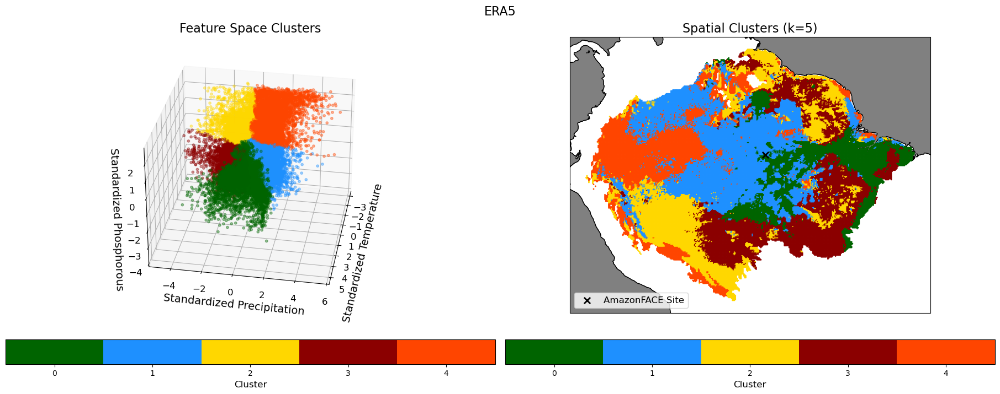

Cluster 0: mean distance to centroid = 2.402, std = 1.159
Cluster 1: mean distance to centroid = 1.830, std = 0.684
Cluster 2: mean distance to centroid = 1.955, std = 0.894
Cluster 3: mean distance to centroid = 1.863, std = 0.900
Cluster 4: mean distance to centroid = 2.473, std = 1.185


In [6]:
era_kmeans, era_kmeans_labels, era_n, era_dist_to_centroids = kmeans_clustering_fit(df_era_trans, n=5)
plot_clusters(df_era_trans, era_kmeans_labels, shared_plot=False, title = "ERA5")
#for each cluster print dist_to_centroids mean and std
for i in range(era_n):
    print(f"Cluster {i}: mean distance to centroid = {era_dist_to_centroids[era_kmeans_labels == i].mean():.3f}, std = {era_dist_to_centroids[era_kmeans_labels == i].std(ddof=1):.3f}")

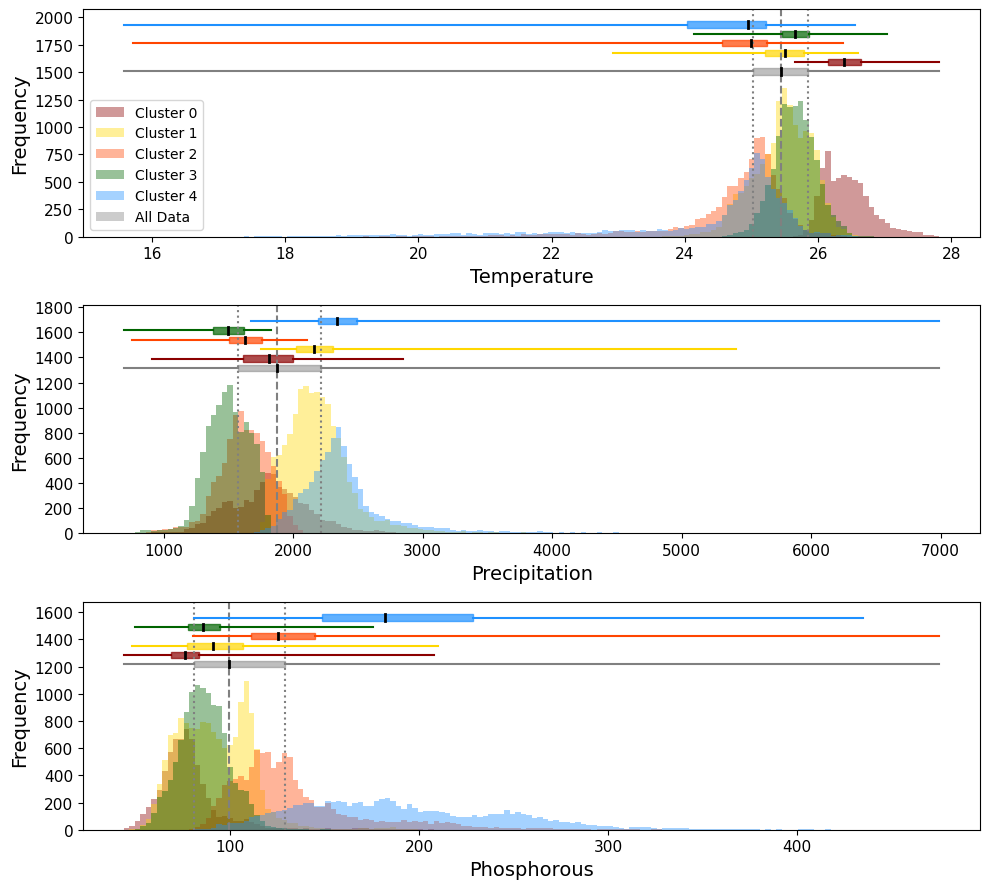

In [7]:
plot_marg_dist_new(df_era, era_kmeans_labels, era_n)


In [136]:

# #print how many std above mean the blue cluster is for phosphorous
# blue_cluster_index = 3  # Assuming blue cluster corresponds to index 3
# blue_cluster_phosphorous = df_era.loc[era_kmeans_labels == blue_cluster_index, 'Phosphorous']
# blue_cluster_mean = blue_cluster_phosphorous.mean()
# blue_cluster_std = blue_cluster_phosphorous.std(ddof=1)
# overall_mean = df_era['Phosphorous'].mean()
# num_std_above_mean = (blue_cluster_mean - overall_mean) / blue_cluster_std
# print(f"Blue cluster (Cluster {blue_cluster_index}) mean Phosphorous is {num_std_above_mean:.2f} standard deviations above the overall mean.")

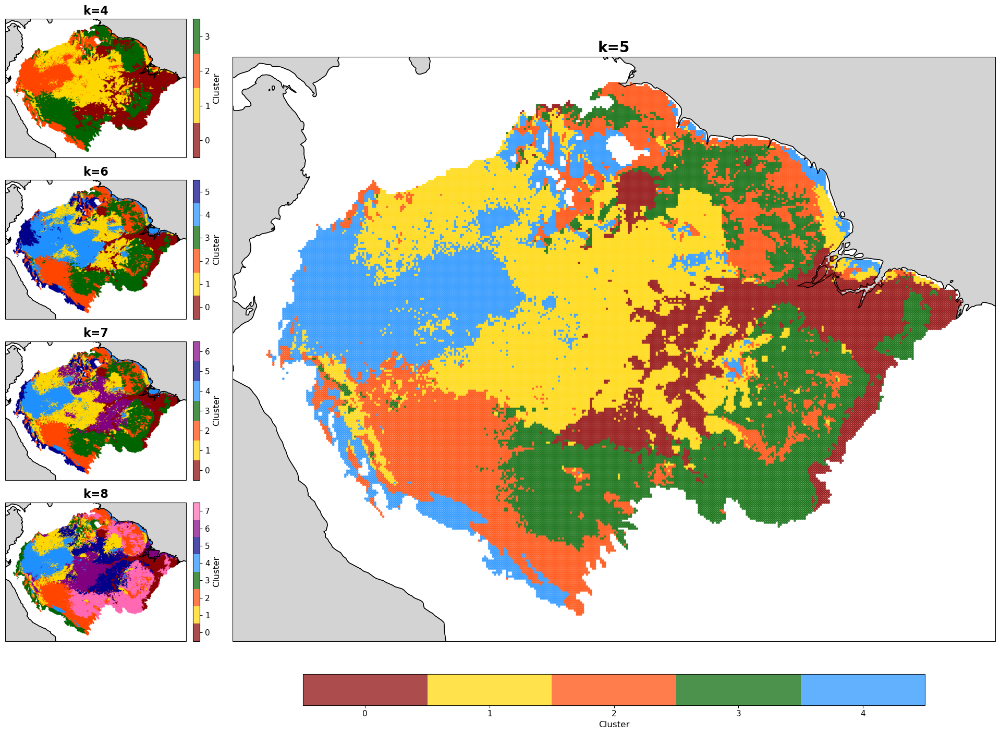

({4: KMeans(n_clusters=4, random_state=42),
  5: KMeans(n_clusters=5, random_state=42),
  6: KMeans(n_clusters=6, random_state=42),
  7: KMeans(n_clusters=7, random_state=42),
  8: KMeans(random_state=42)},
 {4: array([3, 3, 3, ..., 3, 3, 3], shape=(52915,), dtype=int32),
  5: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32),
  6: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32),
  7: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32),
  8: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32)})

In [8]:
plot_cluster_maps_multi_k(df_era_trans, random_state=42, point_size=1)

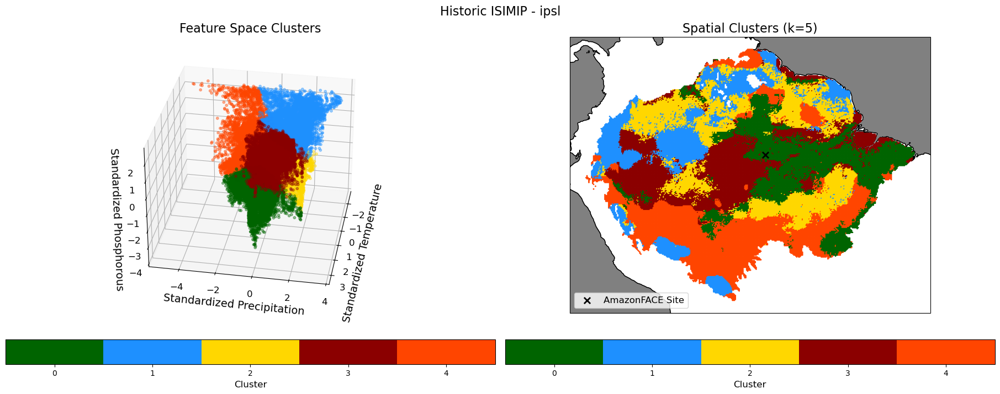

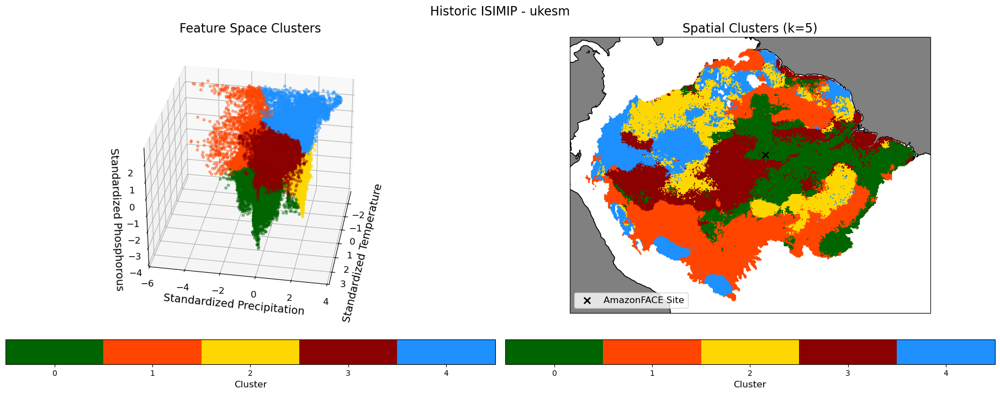

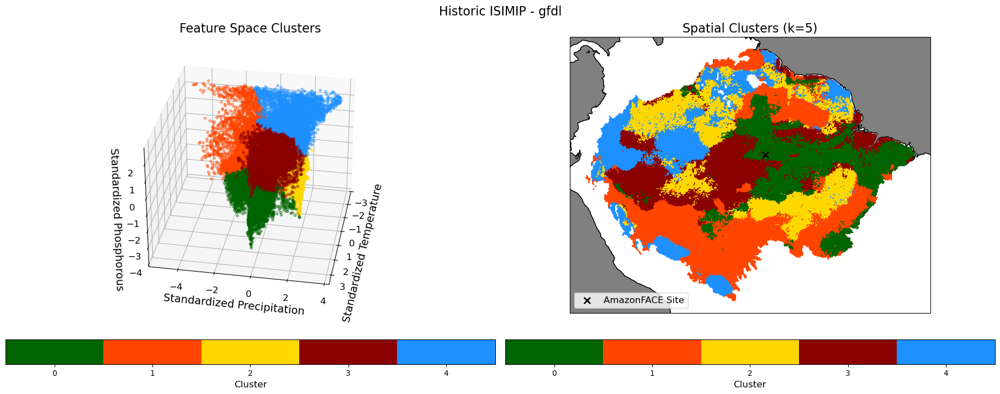

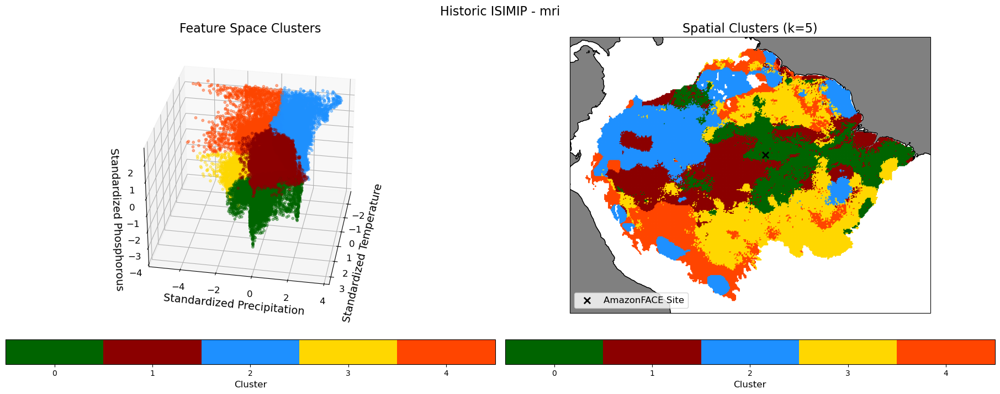

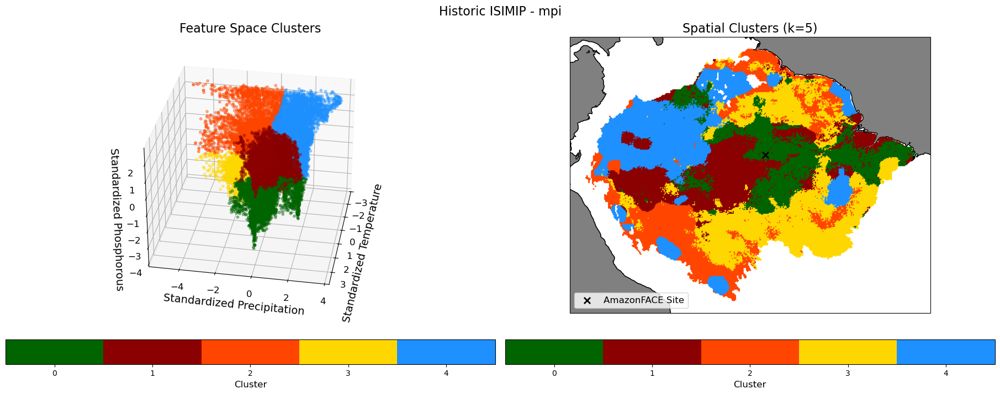

In [9]:
for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    model_df = globals()[f"df_{m}"]
    model_df_trans = globals()[f"df_trans_{m}"]

    driving_kmeans, driving_labels, driving_n, driving_dist_to_centroids = kmeans_clustering_fit(model_df_trans, n=5)
    globals()[f"{m}_driving_labels"] = driving_labels
    plot_clusters(model_df_trans, driving_labels, title = f"Historic ISIMIP - {m}", shared_plot=False, model = m)


In [10]:
#loop through each driving labels and renumber them (ipsl stays) (ukesm 4->1, 1->4) (gfdl 4->1, 1->4) (mri 4->1, 1->4) (mpi 2->1, 3->2, 1->3) (mpi 4->1, 3->2, 1_3, 2->4)
for m in ["ukesm", "gfdl", "mri", "mpi"]:
    driving_labels = globals()[f"{m}_driving_labels"]
    if m == "ukesm":
        # Reorder: 4->1, 1->4
        new_order = {0: 0, 1: 4, 2: 2, 3: 3, 4: 1}
    elif m == "gfdl":
        # Reorder: 4->1, 1->4
        new_order = {0: 0, 1: 4, 2: 2, 3: 3, 4: 1}
    elif m == "mri":
        # Reorder: 4->1, 1->4
        new_order = {0: 0, 1: 3, 2: 1, 3: 2, 4: 4}
    elif m == "mpi":
        # Reorder: 2->1, 3->2, 1->3, and then adjust for the last one
        new_order = {0: 0, 1: 3, 2: 4, 3: 2, 4: 1}

    reordered_labels = np.vectorize(new_order.get)(driving_labels)
    globals()[f"{m}_driving_labels"] = reordered_labels

# plot spatial 5 subplots for each driving model, with the number 1 cluster in blue and all others in grey
# fig, axes = plt.subplots(1, 5, figsize=(20, 4), constrained_layout=True, subplot_kw={'projection': ccrs.PlateCarree()})
# for idx, m in enumerate(["ipsl", "ukesm", "gfdl", "mri", "mpi"]):
#     model_df = globals()[f"df_{m}"]
#     driving_labels = globals()[f"{m}_driving_labels"]
#     axes[idx].scatter(
#         model_df['Longitude'], model_df['Latitude'],
#         c=np.where(driving_labels == 3, 'darkred', 'lightgrey'),
#         s=1,
#         alpha=0.7,
#         transform=ccrs.PlateCarree()
#     )
#     axes[idx].coastlines()
#     axes[idx].add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
#     axes[idx].set_title(f"{m.upper()} Driving Model", fontsize=14)
# plt.suptitle("Spatial Distribution of Cluster 3 (red) vs Others (Grey)", fontsize=16)
# plt.show()

IPSL appears in consensus models: 95.87% of the time (excluding 'No Consensus')
UKESM appears in consensus models: 92.44% of the time (excluding 'No Consensus')
GFDL appears in consensus models: 94.31% of the time (excluding 'No Consensus')
MRI appears in consensus models: 70.34% of the time (excluding 'No Consensus')
MPI appears in consensus models: 67.79% of the time (excluding 'No Consensus')


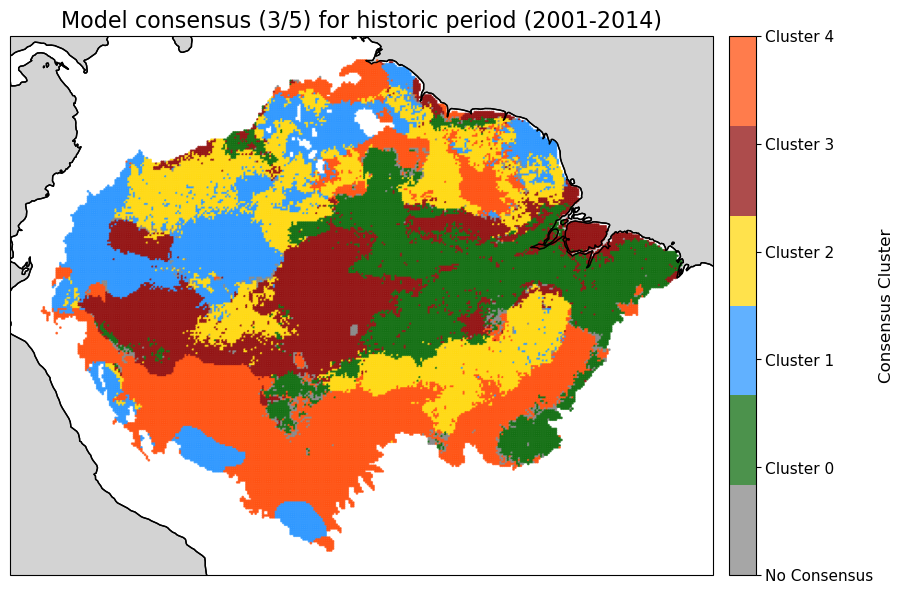

In [37]:
cluster_df = pd.DataFrame({
    'ipsl': globals()['ipsl_driving_labels'],
    'ukesm': globals()['ukesm_driving_labels'],
    'gfdl': globals()['gfdl_driving_labels'],
    'mri': globals()['mri_driving_labels'],
    'mpi': globals()['mpi_driving_labels']
})

q=3

cluster_df['consensus'] = cluster_df.apply(
    lambda row: row.value_counts().index[0]
    if row.value_counts().iloc[0] >= q else -1,
    axis=1
)


#add a column which lists the names of the 3+ models which agree on the consensus cluster, or "No Consensus" if there is no consensus
cluster_df['consensus_models'] = cluster_df.apply(
    lambda row: ', '.join(row.index[row == row.value_counts().index[0]].tolist())
    if row.value_counts().iloc[0] >= q else 'No Consensus',
    axis=1
)

#print out the percentage that each model name appears in the consensus_models column, excluding "No Consensus"
for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    count = cluster_df['consensus_models'].str.contains(m).sum()
    total = len(cluster_df) - (cluster_df['consensus_models'] == 'No Consensus').sum()
    percentage = (count / total) * 100 if total > 0 else 0
    print(f"{m.upper()} appears in consensus models: {percentage:.2f}% of the time (excluding 'No Consensus')")



# cluster_df['consensus'] = cluster_df.apply(lambda row: row[0] if (row == row[0]).all() else -1, axis=1)

#spatial plot of cluster_df coloring by consensus column, with -1 in grey and 0-4 in the same colors as before
cmap_consensus = plt.cm.colors.ListedColormap(['grey', 'darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered'])
fig, ax = plt.subplots(figsize=(10, 7), subplot_kw={'projection': ccrs.PlateCarree()})
scatter = ax.scatter(
    df_ipsl['Longitude'], df_ipsl['Latitude'],
    c=cluster_df['consensus'],
    cmap=cmap_consensus,
    vmin=-1, vmax=4,
    s=1,
    alpha=0.7,
    transform=ccrs.PlateCarree()
)
ax.coastlines()
ax.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
ax.set_title("Model consensus (3/5) for historic period (2001-2014)", fontsize=16)
cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.046, pad=0.02)
cbar.set_ticks([-1, 0, 1, 2, 3, 4])
cbar.set_ticklabels(['No Consensus', 'Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3', 'Cluster 4'])
cbar.set_label('Consensus Cluster', fontsize=12)
cbar.ax.tick_params(labelsize=11)
plt.show()

In [29]:
#print percentage of points that have consensus (i.e., consensus != -1)
consensus_count = (cluster_df['consensus'] != -1).sum()
total_count = len(cluster_df)
consensus_percentage = (consensus_count / total_count) * 100
print(f"Percentage of points with consensus (3/5): {consensus_percentage:.2f}%")

Percentage of points with consensus (3/5): 54.32%


In [ ]:
model_sets = [
    ['ipsl', 'ukesm', 'gfdl'],
    ['ipsl', 'ukesm', 'mri'],
    ['ipsl', 'ukesm', 'mpi'],
    ['ipsl', 'gfdl', 'mri'],
    ['ipsl', 'gfdl', 'mpi'],
    ['ipsl', 'mri', 'mpi'],
    ['ukesm', 'gfdl', 'mri'],
    ['ukesm', 'gfdl', 'mpi'],
    ['ukesm', 'mri', 'mpi'],
    ['gfdl', 'mri', 'mpi']

]

for models in model_sets:
    agreement_mask = cluster_proj_df[models].nunique(axis=1).eq(1)

    # % of all points
    percentage_all = agreement_mask.mean() * 100

    # % of consensus (non-grey) points only
    consensus_mask = cluster_proj_df['consensus'] != -1
    percentage_consensus = (
        agreement_mask[consensus_mask].mean() * 100
        if consensus_mask.any() else 0.0
    )

    model_names = ', '.join(m.upper() for m in models)
    print(f"{model_names} agreement (all points): {percentage_all:.2f}%")
    print(f"{model_names} agreement (consensus / non-grey points): {percentage_consensus:.2f}%")

Percentage of points with IPSL, UKESM, GFDL in agreement: 86.16%
Percentage of points with IPSL, UKESM, MRI in agreement: 58.54%
Percentage of points with IPSL, UKESM, MPI in agreement: 56.42%
Percentage of points with IPSL, GFDL, MRI in agreement: 61.11%
Percentage of points with IPSL, GFDL, MPI in agreement: 58.42%
Percentage of points with IPSL, MRI, MPI in agreement: 61.00%
Percentage of points with UKESM, GFDL, MRI in agreement: 59.56%
Percentage of points with UKESM, GFDL, MPI in agreement: 57.35%
Percentage of points with UKESM, MRI, MPI in agreement: 58.03%
Percentage of points with GFDL, MRI, MPI in agreement: 59.47%


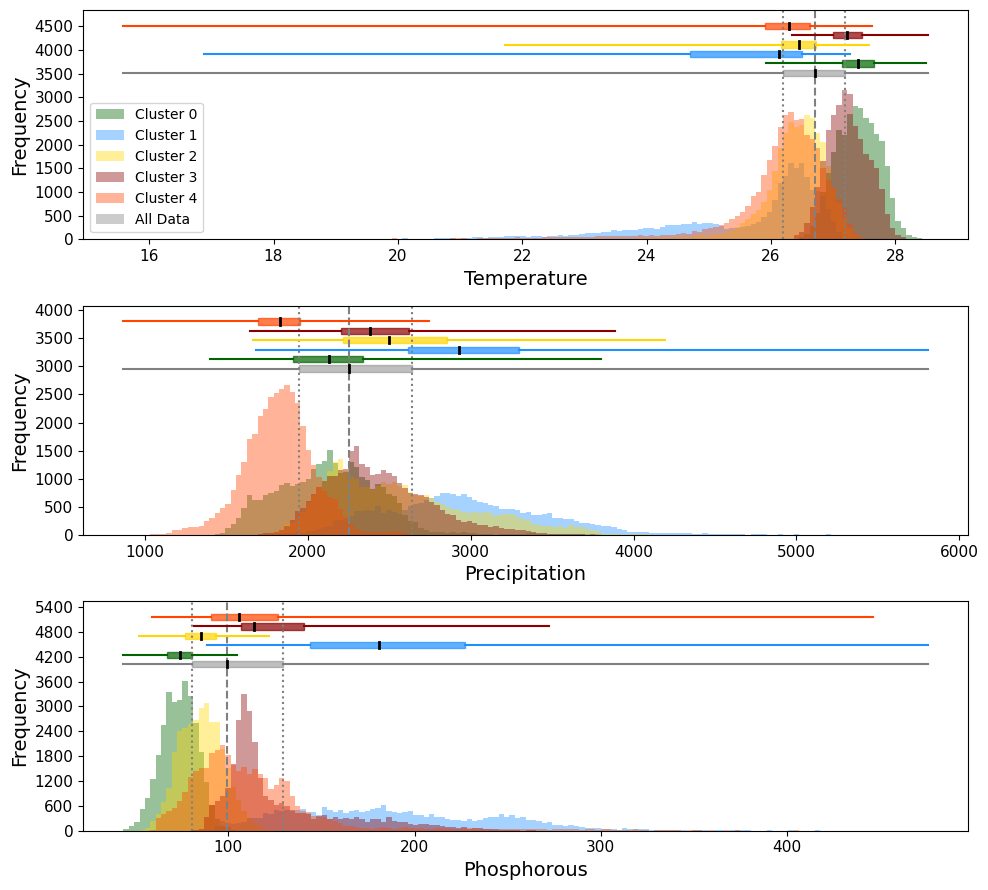

In [38]:
# make a df which is temp, precip and phosphouros, and the consensus cluster, for the ipsl, ukesm and gfdl data flattened and concatenated
combined_df = pd.DataFrame({
    'Temperature': pd.concat([df_ipsl['Temperature'], df_ukesm['Temperature'], df_gfdl['Temperature']], ignore_index=True),
    'Precipitation': pd.concat([df_ipsl['Precipitation'], df_ukesm['Precipitation'], df_gfdl['Precipitation']], ignore_index=True),
    'Phosphorous': pd.concat([df_ipsl['Phosphorous'], df_ukesm['Phosphorous'], df_gfdl['Phosphorous']], ignore_index=True),
    'Consensus Cluster': pd.concat([cluster_df['consensus'], cluster_df['consensus'], cluster_df['consensus']], ignore_index=True)
})

#remove rows with no consensus
combined_df = combined_df[combined_df['Consensus Cluster'] != -1]

labels = combined_df['Consensus Cluster'].values

#removes the consensus cluster column from the df
combined_df = combined_df.drop(columns=['Consensus Cluster'])

plot_marg_dist_new(combined_df, labels, 5, combined = True)


In [13]:
# for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
#     model_df = globals()[f"df_{m}"]
#     model_df_trans = globals()[f"df_trans_{m}"]

#     driving_kmeans, driving_labels, driving_n, driving_dist_to_centroids = kmeans_clustering_fit(model_df_trans, n=5)


#     #spatial plot ipsl trans green cluster only, make all over points black
#     fig, ax = plt.subplots(figsize=(10, 7), subplot_kw={'projection': ccrs.PlateCarree()})
#     # Plot all points in black
#     ax.scatter(
#         model_df_trans['Longitude'], model_df_trans['Latitude'],
#         color='black', s=1, alpha=0.5,
#         transform=ccrs.PlateCarree()
#     )
#     # Highlight green cluster points
#     green_cluster_mask = driving_labels == 1  # Assuming green cluster corresponds to index 0
#     ax.scatter(
#         model_df_trans.loc[green_cluster_mask, 'Longitude'], model_df_trans.loc[green_cluster_mask, 'Latitude'],
#         color='dodgerblue', s=1, alpha=0.8,
#         transform=ccrs.PlateCarree(),
#         label='Green Cluster'
#     )
#     ax.coastlines()
#     ax.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
#     ax.set_title('Historic ISIMIP - IPSL: Blue Cluster Highlighted', fontsize=16)
#     ax.set_xlabel('Longitude', fontsize=14)
#     ax.set_ylabel('Latitude', fontsize=14)  
#     plt.show()

In [14]:
# #not restan

# for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
#     model_df_trans = globals()[f"df_trans_{m}"]
#     model_df_proj = globals()[f"df_proj_trans_{m}"]

#     proj_labels_pred, proj_n_pred, proj_centroids_pred = kmeans_clustering_predict(model_df_trans, model_df_proj, 5)
#     plot_clusters(model_df_proj, proj_labels_pred, title = f"Projected ISIMIP - {m}", shared_plot=False, model = m)

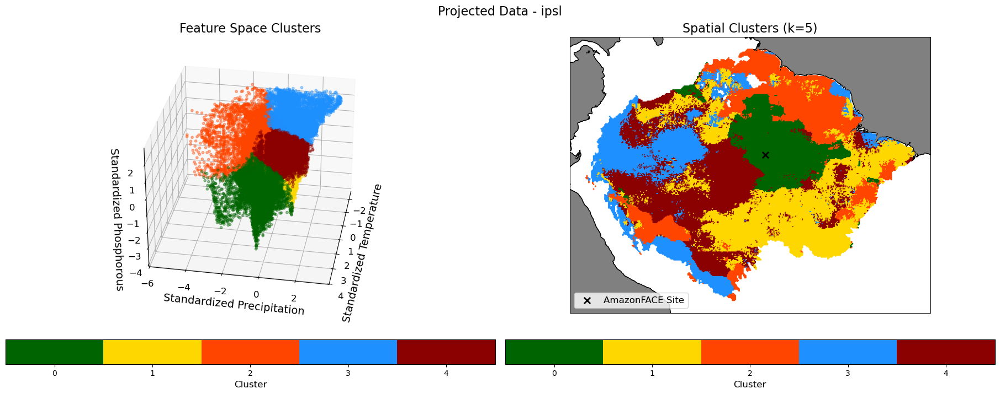

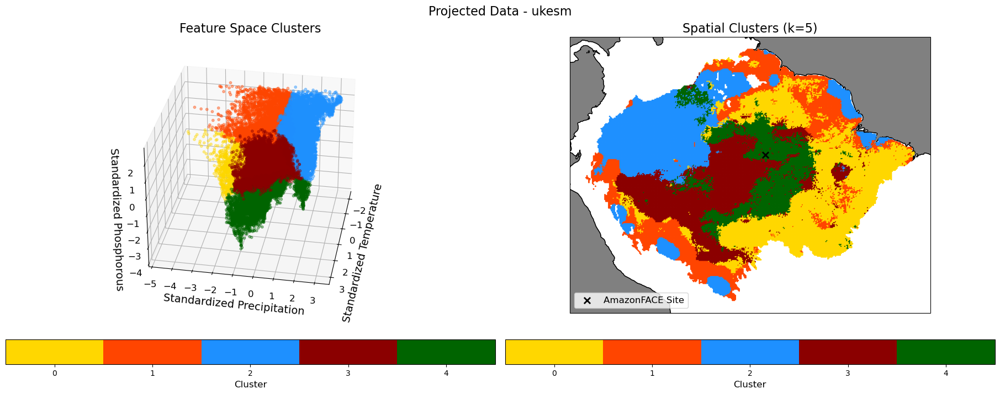

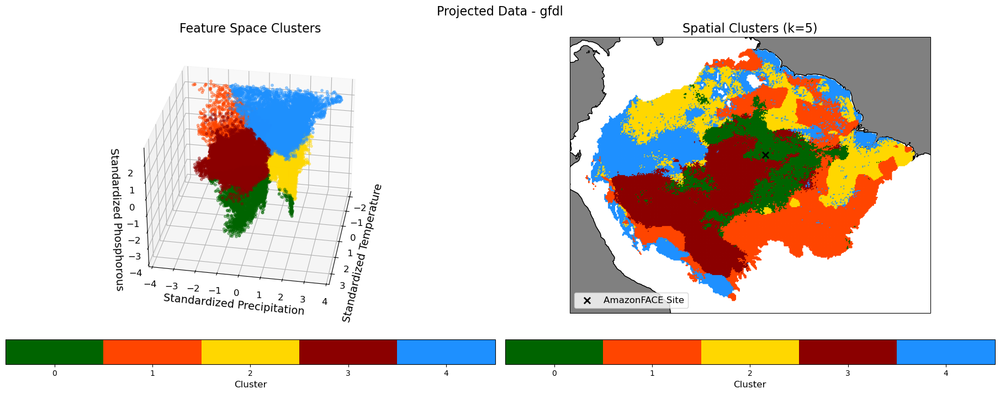

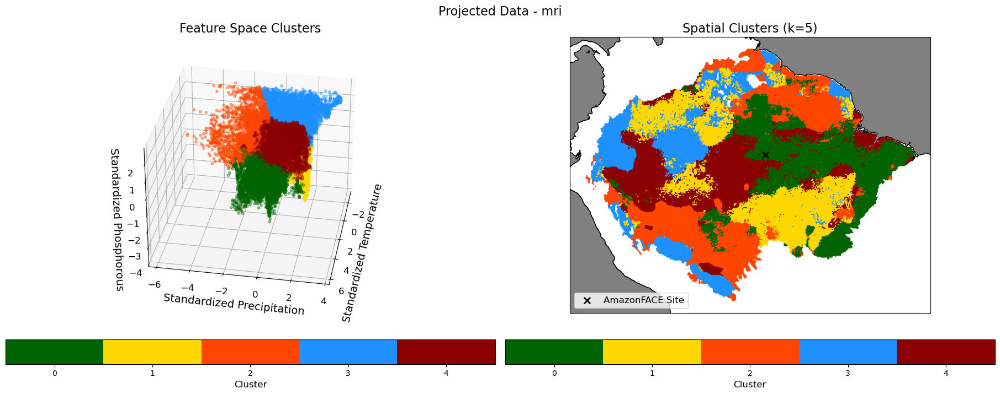

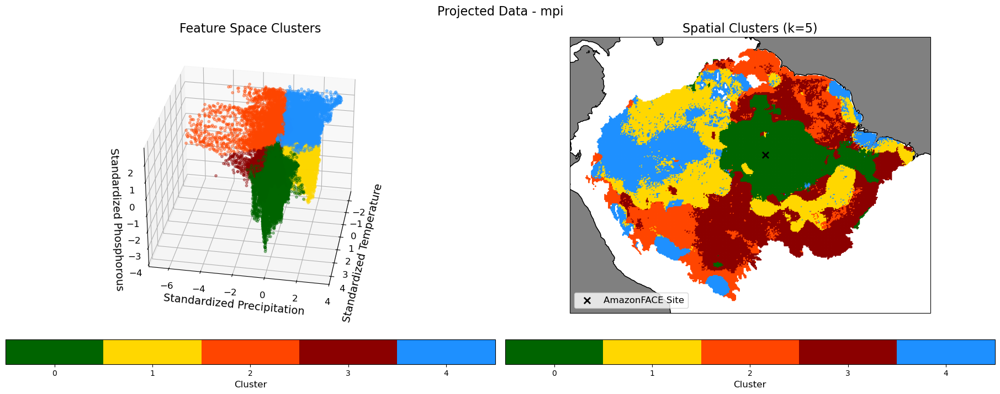

In [31]:
#true restan

for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    model_df_trans = globals()[f"df_trans_{m}"]
    model_df_proj = globals()[f"df_proj_trans_{m}"]

    proj_kmeans, proj_labels, proj_n, proj_dist_to_centroids = kmeans_clustering_fit(model_df_proj, n=5)
    #save the proj_labels to a global variable
    globals()[f"{m}_proj_labels"] = proj_labels
    plot_clusters(model_df_proj, proj_labels, shared_plot=False, title = f"Projected Data - {m}", restan = True, model = m)

In [32]:
#loop through each projected labels and renumber them (ipsl stays) (ukesm 4->1, 1->4) (gfdl 4->1, 1->4) (mri 4->1, 1->4) (mpi 2->1, 3->2, 1->3) (mpi 4->1, 3->2, 1_3, 2->4)
for m in ["ukesm", "gfdl", "mri", "mpi"]:
    projected_labels = globals()[f"{m}_proj_labels"]
    if m == "ukesm":
        new_order = {0: 1, 1: 2, 2: 3, 3: 4, 4: 0}
    elif m == "gfdl":
        new_order = {0: 0, 1: 2, 2: 1, 3: 4, 4: 3}
    elif m == "mri":
        new_order = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4}
    elif m == "mpi":
        new_order = {0: 0, 1: 1, 2: 2, 3: 4, 4: 3}

    reordered_labels = np.vectorize(new_order.get)(projected_labels)
    globals()[f"{m}_proj_labels"] = reordered_labels

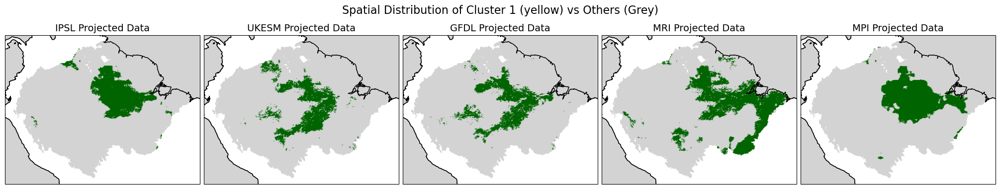

In [100]:
# #using the reodered labels, plot just cluster 1 spatially for all 5 models in a 5 figure subplot colouring them yellow
# fig, axes = plt.subplots(1, 5, figsize=(20, 4), constrained_layout=True, subplot_kw={'projection': ccrs.PlateCarree()})
# for idx, m in enumerate(["ipsl", "ukesm", "gfdl", "mri", "mpi"]):
#     model_df_proj = globals()[f"df_proj_trans_{m}"]
#     proj_labels = globals()[f"{m}_proj_labels"]
#     axes[idx].scatter(
#         model_df_proj['Longitude'], model_df_proj['Latitude'],
#         c=np.where(proj_labels == 0, 'darkgreen', 'lightgrey'),
#         s=1,
#         alpha=0.7,
#         transform=ccrs.PlateCarree()
#     )
#     axes[idx].coastlines()
#     axes[idx].add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
#     axes[idx].set_title(f"{m.upper()} Projected Data", fontsize=14)
# plt.suptitle("Spatial Distribution of Cluster 1 (yellow) vs Others (Grey)", fontsize=16)
# plt.show()

IPSL appears in consensus models: 85.41% of the time (excluding 'No Consensus')
UKESM appears in consensus models: 76.82% of the time (excluding 'No Consensus')
GFDL appears in consensus models: 77.92% of the time (excluding 'No Consensus')
MRI appears in consensus models: 82.20% of the time (excluding 'No Consensus')
MPI appears in consensus models: 68.01% of the time (excluding 'No Consensus')


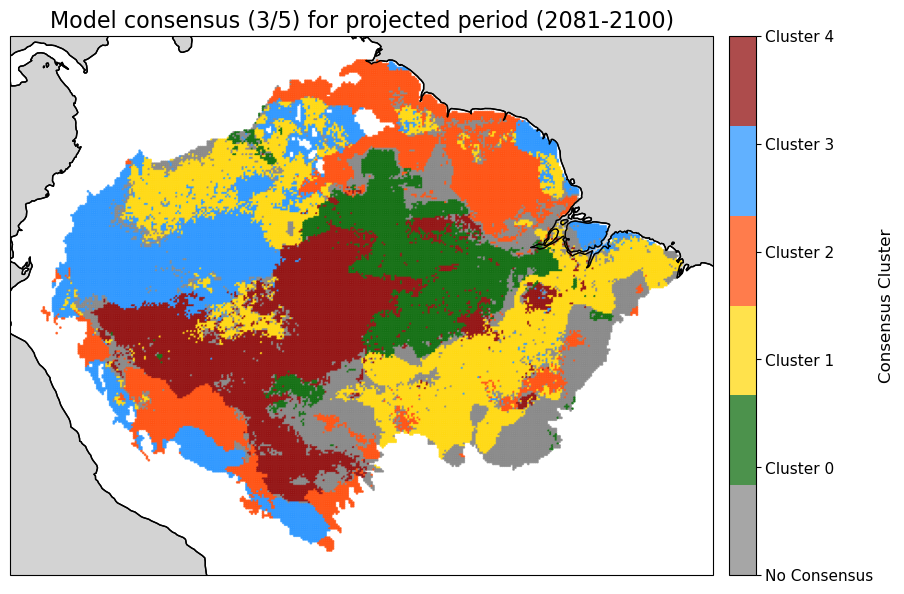

In [45]:
cluster_proj_df = pd.DataFrame({
    'ipsl': globals()['ipsl_proj_labels'],
    'ukesm': globals()['ukesm_proj_labels'],
    'gfdl': globals()['gfdl_proj_labels'],
    'mri': globals()['mri_proj_labels'],
    'mpi': globals()['mpi_proj_labels']
})

q=3

cluster_proj_df['consensus'] = cluster_proj_df.apply(
    lambda row: row.value_counts().index[0]
    if row.value_counts().iloc[0] >= q else -1,
    axis=1
)

#add a column which lists the names of the 3+ models which agree on the consensus cluster, or "No Consensus" if there is no consensus
cluster_proj_df['consensus_models'] = cluster_proj_df.apply(
    lambda row: ', '.join(row.index[row == row.value_counts().index[0]].tolist())
    if row.value_counts().iloc[0] >= q else 'No Consensus',
    axis=1
)

#print out the percentage that each model name appears in the consensus_models column, excluding "No Consensus"
for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    count = cluster_proj_df['consensus_models'].str.contains(m).sum()
    total = len(cluster_proj_df) - (cluster_proj_df['consensus_models'] == 'No Consensus').sum()
    percentage = (count / total) * 100 if total > 0 else 0
    print(f"{m.upper()} appears in consensus models: {percentage:.2f}% of the time (excluding 'No Consensus')")



# cluster_df['consensus'] = cluster_df.apply(lambda row: row[0] if (row == row[0]).all() else -1, axis=1)

#spatial plot of cluster_df coloring by consensus column, with -1 in grey and 0-4 in the same colors as before
cmap_consensus = plt.cm.colors.ListedColormap(['grey', 'darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'])
fig, ax = plt.subplots(figsize=(10, 7), subplot_kw={'projection': ccrs.PlateCarree()})
scatter = ax.scatter(
    df_ipsl['Longitude'], df_ipsl['Latitude'],
    c=cluster_proj_df['consensus'],
    cmap=cmap_consensus,
    vmin=-1, vmax=4,
    s=1,
    alpha=0.7,
    transform=ccrs.PlateCarree()
)
ax.coastlines()
ax.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
ax.set_title("Model consensus (3/5) for projected period (2081-2100)", fontsize=16)
cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.046, pad=0.02)
cbar.set_ticks([-1, 0, 1, 2, 3, 4])
cbar.set_ticklabels(['No Consensus', 'Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3', 'Cluster 4'])
cbar.set_label('Consensus Cluster', fontsize=12)
cbar.ax.tick_params(labelsize=11)
plt.show()

In [44]:
model_sets = [
    ['ipsl', 'ukesm', 'gfdl'],
    ['ipsl', 'ukesm', 'mri'],
    ['ipsl', 'ukesm', 'mpi'],
    ['ipsl', 'gfdl', 'mri'],
    ['ipsl', 'gfdl', 'mpi'],
    ['ipsl', 'mri', 'mpi'],
    ['ukesm', 'gfdl', 'mri'],
    ['ukesm', 'gfdl', 'mpi'],
    ['ukesm', 'mri', 'mpi'],
    ['gfdl', 'mri', 'mpi']

]

for models in model_sets:
    agreement = cluster_proj_df[models].nunique(axis=1).eq(1).sum()
    percentage = agreement / len(cluster_proj_df) * 100
    print(f"Percentage of points with {', '.join(m.upper() for m in models)} in agreement: {percentage:.2f}%")

Percentage of points with IPSL, UKESM, GFDL in agreement: 43.62%
Percentage of points with IPSL, UKESM, MRI in agreement: 44.81%
Percentage of points with IPSL, UKESM, MPI in agreement: 35.81%
Percentage of points with IPSL, GFDL, MRI in agreement: 43.35%
Percentage of points with IPSL, GFDL, MPI in agreement: 36.00%
Percentage of points with IPSL, MRI, MPI in agreement: 40.72%
Percentage of points with UKESM, GFDL, MRI in agreement: 38.12%
Percentage of points with UKESM, GFDL, MPI in agreement: 33.12%
Percentage of points with UKESM, MRI, MPI in agreement: 32.18%
Percentage of points with GFDL, MRI, MPI in agreement: 35.77%


In [34]:
#print what percentage of the input points which have consensus (i.e., consensus != -1)
consensus_count_proj = (cluster_proj_df['consensus'] != -1).sum()
total_count_proj = len(cluster_proj_df)
consensus_percentage_proj = (consensus_count_proj / total_count_proj) * 100
print(f"Percentage of points with consensus (3/5) in projected data: {consensus_percentage_proj:.2f}%") 

Percentage of points with consensus (3/5) in projected data: 24.23%


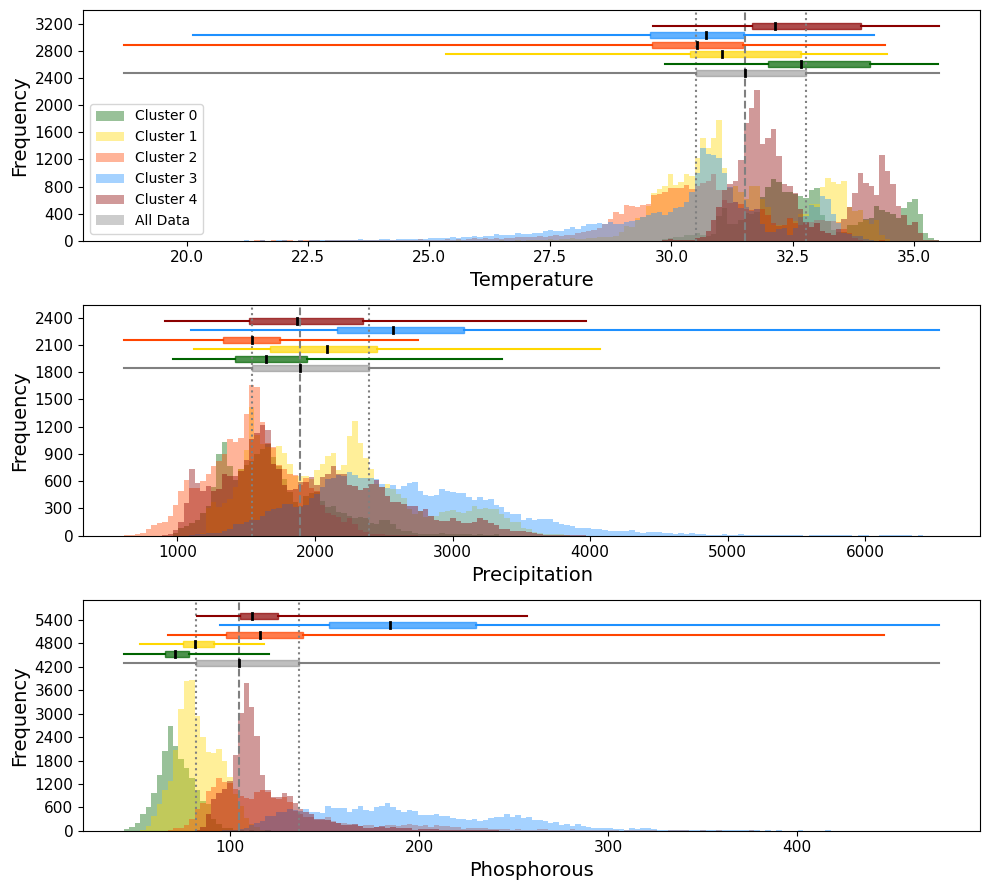

In [155]:
# make a df which is temp, precip and phosphouros, and the consensus cluster, for the ipsl, ukesm and gfdl data flattened and concatenated
combined_proj_df = pd.DataFrame({
    'Temperature': pd.concat([df_proj_ipsl['Temperature'], df_proj_ukesm['Temperature'], df_proj_gfdl['Temperature']], ignore_index=True),
    'Precipitation': pd.concat([df_proj_ipsl['Precipitation'], df_proj_ukesm['Precipitation'], df_proj_gfdl['Precipitation']], ignore_index=True),
    'Phosphorous': pd.concat([df_proj_ipsl['Phosphorous'], df_proj_ukesm['Phosphorous'], df_proj_gfdl['Phosphorous']], ignore_index=True),
    'Consensus Cluster': pd.concat([cluster_proj_df['consensus'], cluster_proj_df['consensus'], cluster_proj_df['consensus']], ignore_index=True)
})

#remove rows with no consensus
combined_proj_df = combined_proj_df[combined_proj_df['Consensus Cluster'] != -1]

proj_labels = combined_proj_df['Consensus Cluster'].values

#removes the consensus cluster column from the df
combined_proj_df = combined_proj_df.drop(columns=['Consensus Cluster'])

plot_marg_dist_new(combined_proj_df, proj_labels, 5, combined = True, reorder_colors = True)

In [156]:
# plot_marg_dist_new(df, driving_labels, driving_n, reorder_colors=True)

In [157]:
# proj_labels_pred, proj_n_pred, proj_centroids_pred = kmeans_clustering_predict(df_trans, df_proj_trans, 5)
# plot_clusters(df_proj_trans, proj_labels_pred, reorder_colors = True, title = "Projected ISIMIP", shared_plot=False, ukesm = True)

In [158]:
# proj_kmeans, proj_labels, proj_n, proj_dist_to_centroids = kmeans_clustering_fit(df_proj_trans, n=5)
# plot_clusters(df_proj_trans, proj_labels, reorder_colors = True, shared_plot=False, title = "Projected Data", restan = True)

In [159]:
# plot_marg_dist_new(df_proj, proj_labels, proj_n, reorder_colors=True, restan=True)

In [162]:
combined_df.head()

,Temperature,Precipitation,Phosphorous
0,26.261934,1420.961590,246.651108
1,26.214010,1475.779165,246.663467
2,26.166086,1530.596741,240.648026
3,26.118164,1585.414317,232.815155
4,26.126333,1647.130948,230.949341


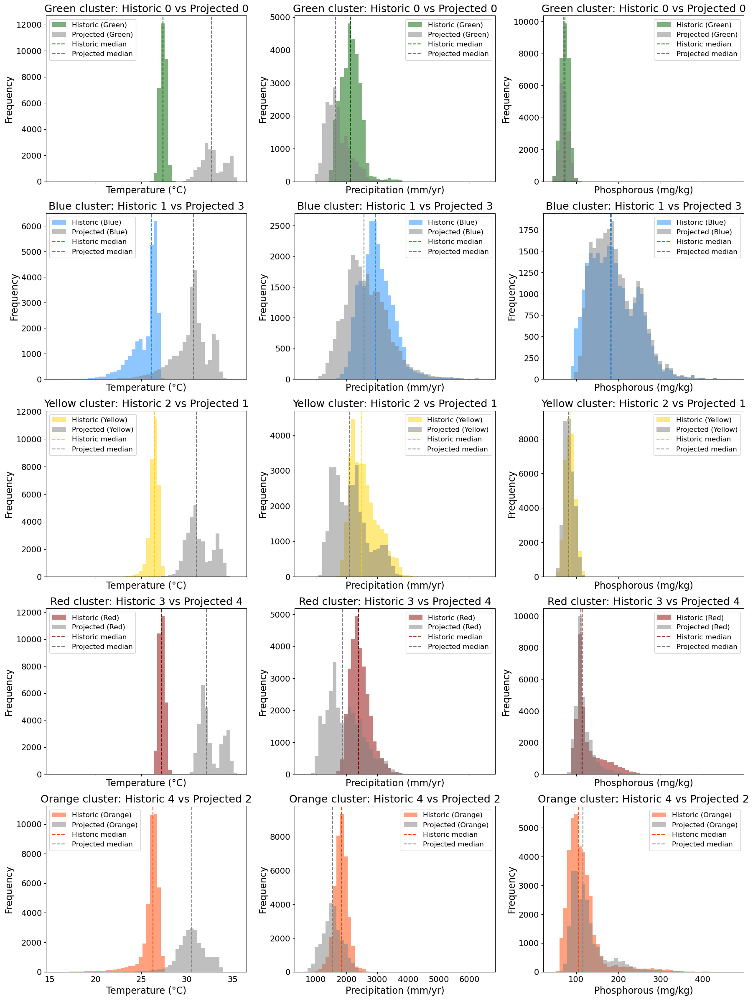

In [163]:
# Validate expected columns before plotting
features = ['Temperature', 'Precipitation', 'Phosphorous']
units = ['°C', 'mm/yr', 'mg/kg']

for name, d in [('combined_df', combined_df), ('combined_proj_df', combined_proj_df)]:
    missing = [c for c in features if c not in d.columns]
    if missing:
        raise KeyError(f"{name} is missing columns: {missing}. Available: {list(d.columns)}")

fig, axes = plt.subplots(5, 3, figsize=(18, 24), sharex='col')

# Larger text settings
label_fs = 16
title_fs = 18
tick_fs = 14
legend_fs = 12

# Shared bins per feature
feature_bins = {}
for feature in features:
    feat_min = min(combined_df[feature].min(), combined_proj_df[feature].min())
    feat_max = max(combined_df[feature].max(), combined_proj_df[feature].max())
    feature_bins[feature] = np.linspace(feat_min, feat_max, 51)

# Match clusters by colour between historic and projected label schemes
hist_to_proj = {0: 0, 1: 3, 2: 1, 3: 4, 4: 2}
cluster_colors = {0: 'darkgreen', 1: 'dodgerblue', 2: 'gold', 3: 'darkred', 4: 'orangered'}
cluster_names = {0: 'Green', 1: 'Blue', 2: 'Yellow', 3: 'Red', 4: 'Orange'}

for row, hist_cluster in enumerate(range(5)):
    proj_cluster = hist_to_proj[hist_cluster]
    color = cluster_colors[hist_cluster]
    cname = cluster_names[hist_cluster]

    for col, (feature, unit) in enumerate(zip(features, units)):
        ax = axes[row, col]

        hist_data = combined_df.loc[labels == hist_cluster, feature]
        proj_data = combined_proj_df.loc[proj_labels == proj_cluster, feature]
        bin_edges = feature_bins[feature]

        ax.hist(hist_data, bins=bin_edges, alpha=0.5, color=color, label=f'Historic ({cname})')
        ax.hist(proj_data, bins=bin_edges, alpha=0.5, color='grey', label=f'Projected ({cname})')

        if len(hist_data) > 0:
            ax.axvline(hist_data.median(), color=color, linestyle='--', linewidth=1.5, label='Historic median')
        if len(proj_data) > 0:
            ax.axvline(proj_data.median(), color='grey', linestyle='--', linewidth=1.5, label='Projected median')

        ax.set_xlabel(f'{feature} ({unit})', fontsize=label_fs)
        ax.set_ylabel('Frequency', fontsize=label_fs)
        ax.set_title(f'{cname} cluster: Historic {hist_cluster} vs Projected {proj_cluster}', fontsize=title_fs)
        ax.tick_params(labelsize=tick_fs)
        ax.legend(fontsize=legend_fs)

plt.tight_layout()
plt.show()


In [ ]:
# #ERA 5 has labels 0 red, 1 yellow, 2 purple, 3 green, 4 orange and driving has 0 red, 1 orange, 2 yellow, 3 green, 4 purple so using the labels outputs, work out where a point has changed from one colour to another accounting for this mismatch of colours/numbers
# # Create a mapping from ERA5 cluster labels to driving cluster labels based on the most common label

# #for era labels, make a copy where 1s swap to 4s, 2s to 1s, 4s to 2s
# era_kmeans_labels_reordered = era_kmeans_labels.copy()
# era_kmeans_labels_reordered[era_kmeans_labels == 1] = 2
# era_kmeans_labels_reordered[era_kmeans_labels == 2] = 4
# era_kmeans_labels_reordered[era_kmeans_labels == 4] = 1

# # where era_kmeans_labels_reordered doesnt equal driving_labels, set diff labels to 5, else keep the same
# diff_labels = np.where(era_kmeans_labels_reordered != driving_labels, 5, era_kmeans_labels_reordered)

# # plot the map colours by diff labels
# plot_clusters(df_trans, diff_labels, shared_plot=False)



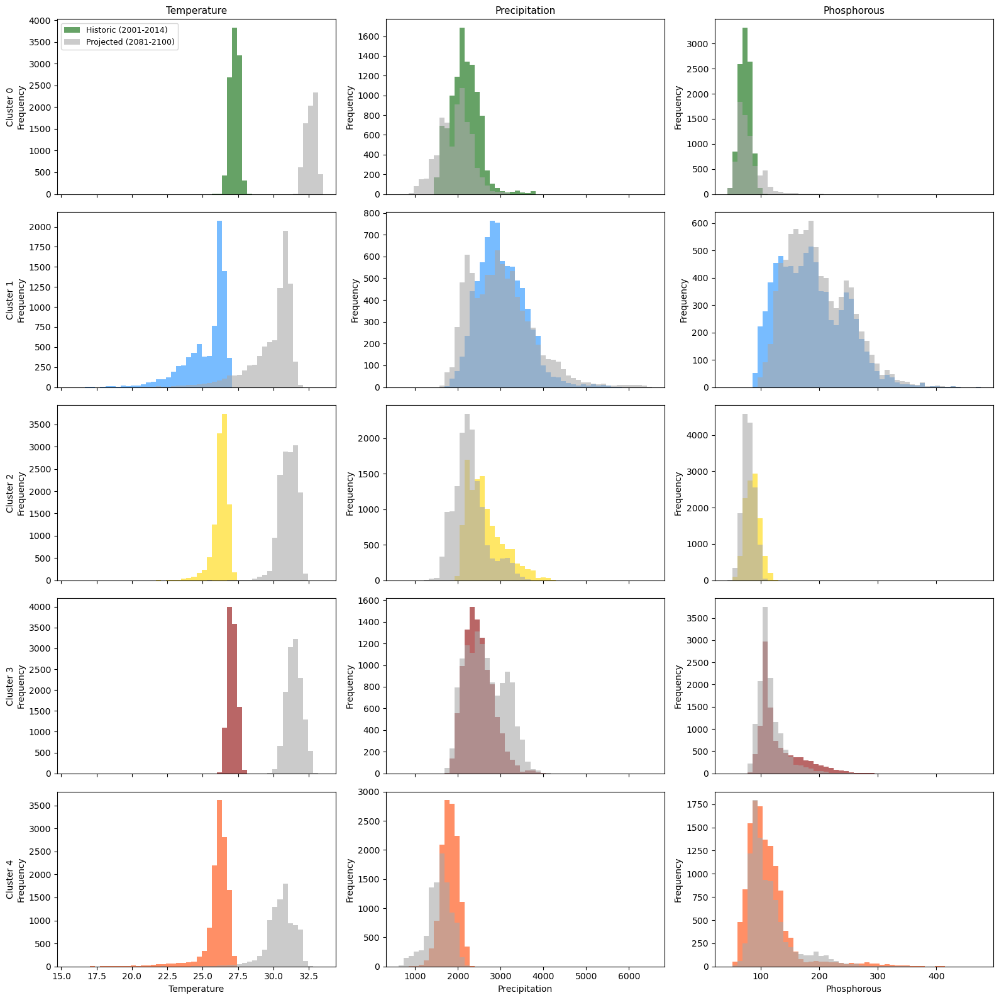

In [ ]:
plot_marg_dist_comparison(df, df_proj, driving_labels, proj_labels, driving_n)

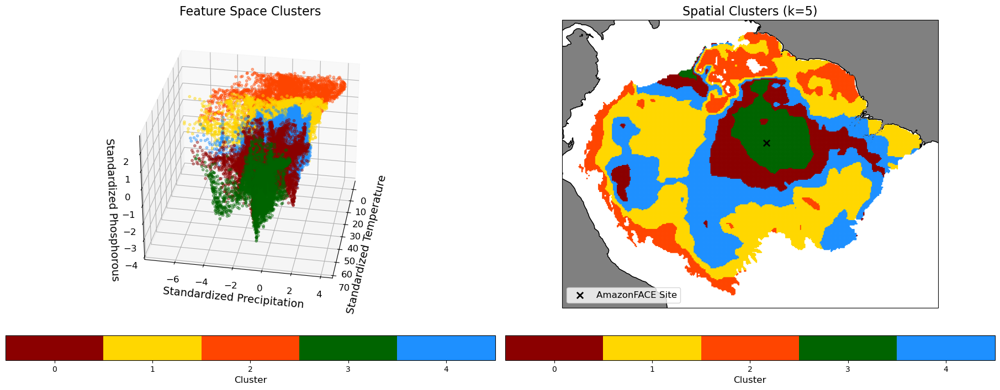

In [ ]:
proj_kmeans_refit, proj_labels_refit, proj_n_refit, proj_refit_centroids = kmeans_clustering_fit(df_proj_trans, n=5)
plot_clusters(df_proj_trans, proj_labels_refit, reorder_colors = False, shared_plot=False)

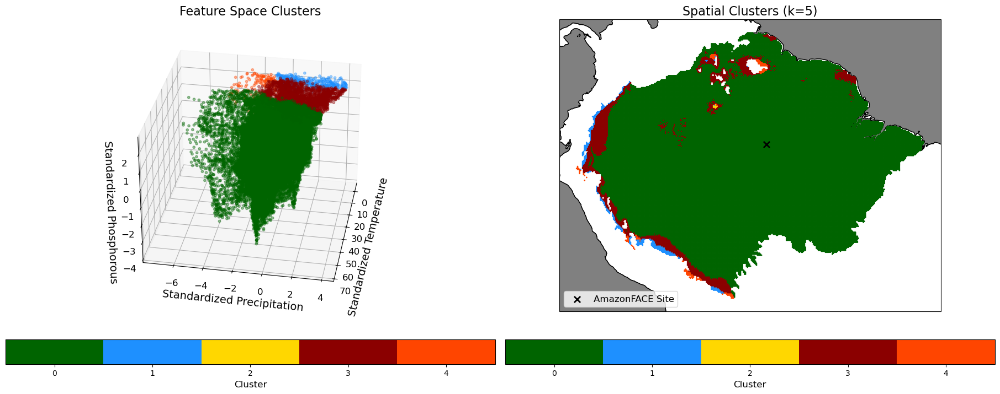

Cluster 0: mean distance to centroid = 25.183, std = 11.149
Cluster 1: mean distance to centroid = 3.070, std = 1.116
Cluster 2: mean distance to centroid = 1.501, std = 0.506
Cluster 3: mean distance to centroid = 7.488, std = 4.080
Cluster 4: mean distance to centroid = 3.062, std = 1.158


In [ ]:
proj_labels, proj_n, proj_dist_to_centroids = kmeans_clustering_predict(df_trans, df_proj_trans, 5)
plot_clusters(df_proj_trans, proj_labels, reorder_colors = True, shared_plot=False)
#calculate silhouette score for projected data clusters
# sil_score_proj = silhouette_score(df_proj_trans[['Temperature', 'Precipitation', 'Phosphorous']], proj_labels)
# print(f'Silhouette Score for projected data clusters: {sil_score_proj:.3f}')    
#for each cluster print dist_to_centroids mean and std
for i in range(proj_n):
    print(f"Cluster {i}: mean distance to centroid = {proj_dist_to_centroids[proj_labels == i].mean():.3f}, std = {proj_dist_to_centroids[proj_labels == i].std(ddof=1):.3f}")

In [ ]:
# hist_dist_to_centroids: array of distances from historic points to centroids
# proj_dist_to_centroids: array of distances from projected points to centroids

results = {}

for k in range(5):
    h = driving_dist_to_centroids[driving_labels == k, k]
    p = proj_dist_to_centroids[proj_labels == k, k]

    # Historical percentiles
    q50 = np.percentile(h, 50)
    q95 = np.percentile(h, 95)
    
    # Novelty rate: projected points above hist 95th percentile
    novelty_rate = np.mean(p > q95)

    # Empirical CDF for p-values
    h_sorted = np.sort(h)
    def emp_pvalue(d):
        # proportion of historical distances <= d
        F = np.searchsorted(h_sorted, d, side='right') / len(h_sorted)
        return 1 - F

    pvals = np.array([emp_pvalue(d) for d in p])
    
    results[k] = {
        "hist_mean": np.mean(h),
        "proj_mean": np.mean(p),
        "hist_95": q95,
        "proj_95": np.percentile(p, 95),
        "novelty_rate": novelty_rate,
        "pval_lt_0.05": np.mean(pvals < 0.05),
        "pval_lt_0.01": np.mean(pvals < 0.01)
    }

results

{0: {'hist_mean': 3.260731702165556,
  'proj_mean': 12.92249241258229,
  'hist_95': 3.837774849004587,
  'proj_95': 13.96013195408395,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 1: {'hist_mean': 3.1302439210157806,
  'proj_mean': 11.846921880193289,
  'hist_95': 3.7511917796029945,
  'proj_95': 12.879987519891635,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 2: {'hist_mean': 2.99332813736108,
  'proj_mean': 10.847251300563872,
  'hist_95': 3.6514467168820453,
  'proj_95': 11.877484385020594,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 3: {'hist_mean': 2.8606992912371885,
  'proj_mean': 9.920877717099376,
  'hist_95': 3.5528389073003703,
  'proj_95': 10.948612247505062,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 4: {'hist_mean': 2.73705707614342,
  'proj_mean': 9.565555775323649,
  'hist_95': 3.459850534871612,
  'proj_95': 10.58528602832143,
  'novelty_rate': 1.0,
  'pval_lt_0.0

In [ ]:
# plot_feature_space(df_trans, driving_labels, proj=False)

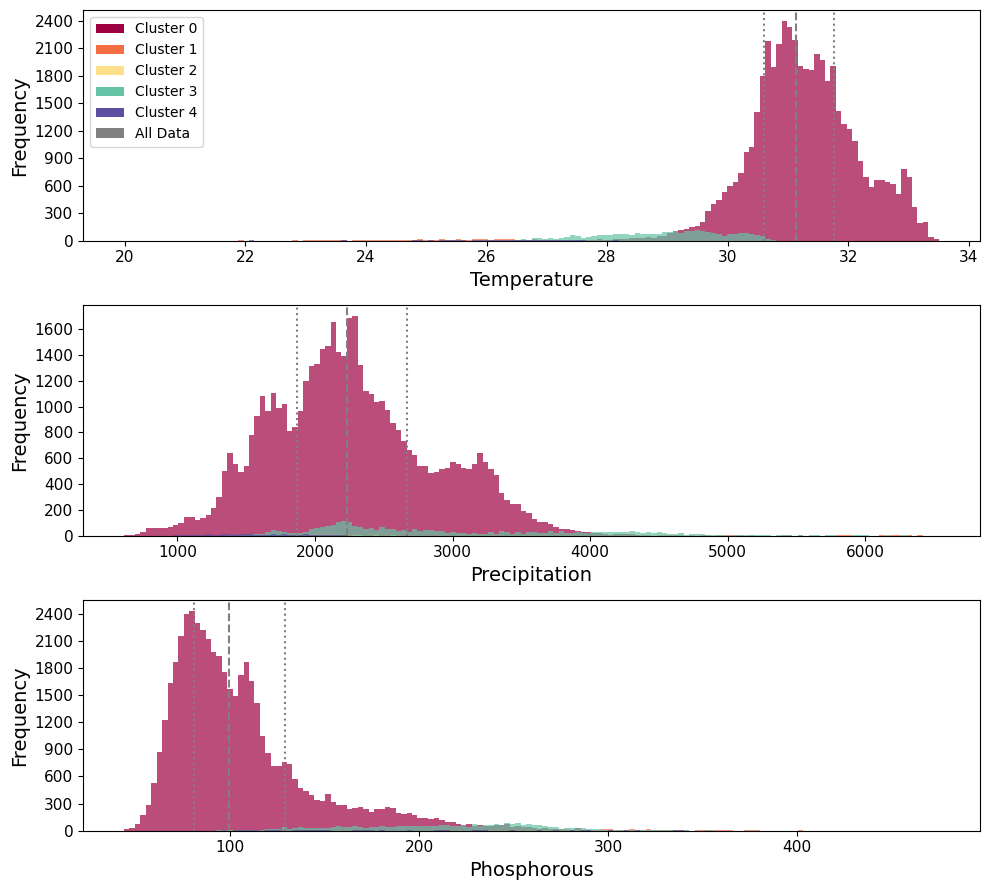

In [ ]:
plot_marg_dist(df_proj, proj_labels, 5, proj=False)

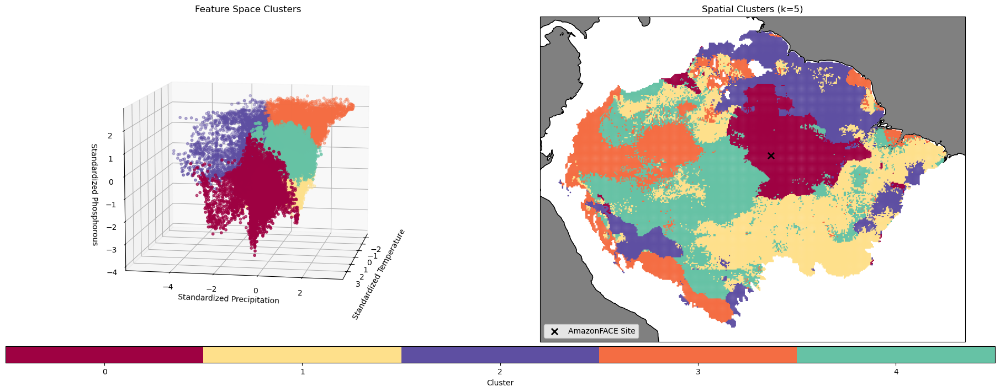

In [ ]:
# proj_kmeans, proj_labels, proj_n = kmeans_clustering_fit(df_proj_trans, n=5)
# plot_clusters(df_proj_trans, proj_labels, proj=True)


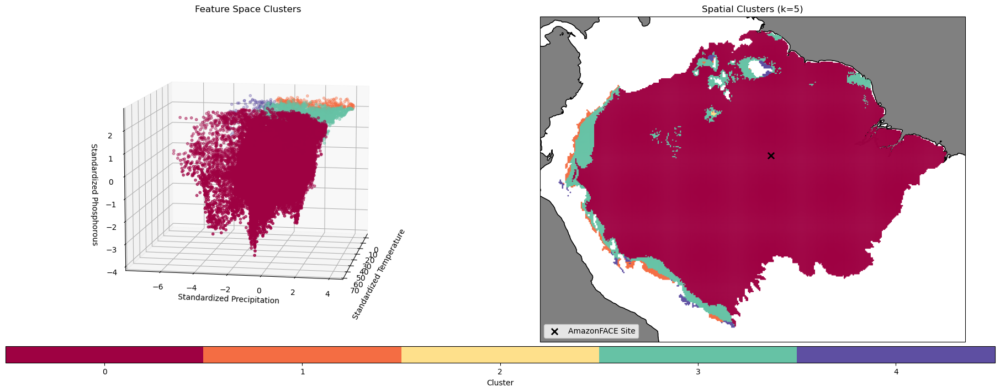

In [ ]:
pred_proj_labels, n = kmeans_clustering_predict(df_trans, df_proj_trans, n=5)
plot_clusters(df_proj_trans, pred_proj_labels, colours = 0)

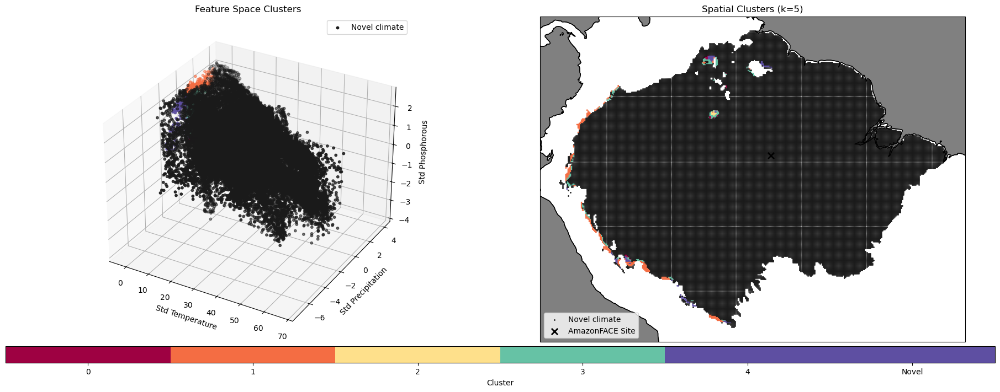

Novel climate percentage in projected data: 98.64%


In [ ]:
novel_kmeans, novel_proj_labels, novel_n = novel(df_trans, df_proj_trans, n=5)
plot_clusters_novel(df_proj_trans, novel_proj_labels, proj=False)

#print percentage of points in novel cluster
novel_percentage = np.mean(novel_proj_labels == 5) * 100
print(f"Novel climate percentage in projected data: {novel_percentage:.2f}%")
